# 05. Evaluación temporal de los escenarios

## 1. ¿Qué necesitamos comprobar después de construir los escenarios?

En la notebook 04 construimos escenarios conjuntos condicionados por grupos de VIX y verificamos su implementación numérica. Eso no demuestra que sus distribuciones representen mejor los movimientos posteriores.

Ahora compararemos pronósticos emitidos usando únicamente el pasado admisible con realizaciones posteriores. Repetiremos el ejercicio cronológicamente: una sola realización no valida una distribución; necesitamos una secuencia de pronósticos y resultados.

Referencia conceptual: Anton Vorobets, *Portfolio Construction and Risk Management*, sección 3.4, *Simulation Evaluation*, páginas impresas 49–53. El protocolo temporal y las métricas concretas serán decisiones de este proyecto.

## Alcance de esta notebook

- Compararemos remuestreo uniforme, exponencial y condicionado por VIX.
- Evaluaremos horizontes de una y cinco sesiones.
- En cada fecha, todos los métodos usarán la misma muestra admisible.
- Cortes, momentos y probabilidades se estimarán con el pasado de esa fecha; no se reutilizarán los ajustes de toda la muestra de 04.
- Examinaremos calidad marginal, dependencia conjunta y aspectos temporales.
- La evaluación es retrospectiva sobre datos ya explorados, no un holdout intacto ni una reconstrucción point-in-time completa.
- El objetivo final es decidir qué generador llevar a una posterior construcción de cartera candidata, o concluir que no hay evidencia suficiente para preferir el condicionado.
- No se evaluará rentabilidad de una estrategia ni se optimizarán carteras en 05.

La siguiente pregunta permanece abierta: **¿En qué momento emitimos cada pronóstico y qué información puede utilizar?**

## 2. ¿Cuándo emitimos el pronóstico y qué información utilizamos?

Antes de comparar modelos debemos separar la información utilizada para ajustarlos del intervalo cuyo retorno evaluaremos.

La convención acordada usa $t$ para una sesión del calendario de acciones publicado. El origen del pronóstico se sitúa inmediatamente antes del cierre de $t$. Usamos retornos históricos fechados hasta $t-1$ y el estado inicial utiliza el cierre VIX de $t-1$, conforme a nuestra convención de disponibilidad. No usamos el retorno de $t$ ni su cierre VIX para ajustar o inicializar el modelo.

| Elemento | Fecha o intervalo |
|---|---|
| Última fecha admisible de retornos de ajuste | $t-1$ |
| Fecha fuente del VIX inicial | $t-1$ |
| Precio de referencia del resultado | Cierre de $t$ |
| Primer retorno evaluado | Fila $t+1$ |
| Último retorno evaluado para $H=5$ | Fila $t+5$ |

Los resultados a evaluar son: para $H=1$, el retorno entre el cierre de $t$ y el cierre de $t+1$; para $H=5$, el retorno acumulado entre el cierre de $t$ y el cierre de $t+5$. Los índices representan sesiones, no días calendario.

El cierre de $t$ sólo se utiliza posteriormente para medir el resultado realizado; no es una entrada del pronóstico. Para la fila $t+1$, el VIX de $t-1$ respeta el rezago $x-2$ de la notebook 04. En los triples históricos de ajuste, tanto los retornos como sus estados deben respetar el límite de información establecido. Cortes, momentos crisp y probabilidades se reconstruirán exclusivamente con la muestra de ajuste de cada origen: no reutilizaremos $Q$, cortes ni momentos calculados sobre toda la muestra de 04.

La disponibilidad del VIX es una convención sustentada en la comunicación del proveedor, no una comprobación histórica point-in-time. La disponibilidad de las entradas sigue siendo un supuesto del experimento retrospectivo; no afirmamos disponer de archivos históricos con timestamps de publicación. Esta convención define un experimento de pronóstico, pero no presupone que podamos ejecutar operaciones al cierre de $t$.

**Ejemplo ilustrativo.** Antes del cierre del lunes, suponiendo sesiones habituales, usaríamos retornos de ajuste hasta el viernes y VIX inicial del viernes. El primer resultado sería el retorno del cierre del lunes al cierre del martes. No se selecciona aquí una fecha real.

Procedencia: la evaluación temporal se relaciona con la sección 3.4 del libro. El momento de emisión y el rezago son decisiones de este proyecto, no reglas atribuidas al autor.

La próxima pregunta es: **¿Cuánta historia utilizaremos para ajustar cada pronóstico y desde cuándo comenzará la evaluación?**

## 3. ¿Cuánta historia utilizamos y cuándo podemos evaluar?

Usaremos una ventana expansiva sobre las observaciones alineadas de 04, con mínimo inicial $M=504$. Cada origen incorpora observaciones nuevas admisibles. La semivida queda fija en $\tau=1102$ sesiones; no se recalcula como mitad de ventana. $M$ es una decisión inicial del proyecto, no un óptimo ni una regla del libro.

Este bloque construye fechas del experimento, no pronósticos: ajuste hasta $t-1$, VIX inicial de $t-1$, y resultados fechados $t+1$ hasta $t+H$, con $H\in\{1,5\}$. El retorno de $t$ no entra al ajuste ni al resultado.

In [1]:
from pathlib import Path
import json, hashlib, site, sys
import numpy as np
def root():
 for p in (Path.cwd(),*Path.cwd().parents):
  for c in (p,p/'scenario-portfolio-lab',p/'data-science-portfolio'/'scenario-portfolio-lab'):
   if (c/'config'/'universe.csv').is_file() and (c/'src'/'scenario_portfolio_lab').is_dir(): return c
 raise RuntimeError('Run from complete scenario-portfolio-lab repository.')
ROOT=root(); sp=ROOT/'.venv'/'Lib'/'site-packages'
if sp.is_dir():site.addsitedir(str(sp))
import polars as pl
RUN=ROOT/'data'/'published'/'cut_2026-10-09_run_2026-10-11_full_window_final'; AROOT=ROOT/'data'/'published'/'vix_state_alignment_2026-10-31'; VROOT=ROOT/'data'/'raw'/'vix_index_access_2026-10-29'
prices=pl.read_parquet(RUN/'gold'/'adjusted_close_matrix.parquet'); returns=pl.read_parquet(RUN/'gold'/'eligible_simple_total_return_matrix.parquet'); eligible=pl.read_csv(RUN/'reports'/'eligible_universe.csv').filter(pl.col('universe_status')=='ELIGIBLE'); audit=pl.read_parquet(AROOT/'vix_return_alignment.parquet').filter(pl.col('alignment_status')=='ALIGNED')
raw=VROOT/'raw'/'VIX_INDEX_DATA_daily.json'; manifest=json.loads((VROOT/'manifest.json').read_text(encoding='utf-8')); assert hashlib.sha256(raw.read_bytes()).hexdigest()==manifest['raw_sha256']
from datetime import date
if prices.columns[0] != returns.columns[0] or prices.columns[0] != 'session_date': raise AssertionError('Expected session_date as the temporal field in both matrices.')
if returns.columns[1:] != eligible['symbol'].to_list() or len(set(eligible['symbol'].to_list())) != 125: raise AssertionError('Eligible catalog identifiers do not match the matrix columns in order.')
vix={date.fromisoformat(x['date']):float(x['close']) for x in json.loads(raw.read_text(encoding='utf-8'))['data']}; cal=prices['session_date'].to_list(); aligned=audit['return_date'].to_list(); M,TAU,HORIZONS=504,1102,(1,5); retset=set(returns['session_date'].to_list())
tables={}
for H in HORIZONS:
 rows=[]
 for i in range(1,len(cal)):
  t,prev=cal[i],cal[i-1]; fit=[d for d in aligned if d<=prev]; future=cal[i+1:i+H+1]; reason='ELIGIBLE'
  if len(fit)<M:reason='INSUFFICIENT_ALIGNED_HISTORY'
  elif prev not in vix:reason='MISSING_INITIAL_VIX'
  elif len(future)!=H or any(d not in retset for d in future):reason='INCOMPLETE_FUTURE_HORIZON'
  rows.append({'H':H,'origin_date':t,'fit_first_return_date':fit[0] if fit else None,'fit_last_return_date':fit[-1] if fit else None,'fit_observations':len(fit),'initial_vix_date':prev,'initial_vix_close':vix.get(prev),'first_evaluated_return_date':future[0] if future else None,'last_evaluated_return_date':future[-1] if future else None,'eligible':reason=='ELIGIBLE','reason':reason})
 tables[H]=pl.DataFrame(rows)
eligible_tables={H:tables[H].filter(pl.col('eligible')) for H in HORIZONS}
controls={'calendar_unique_increasing':cal==sorted(cal) and len(cal)==len(set(cal)),'symbols_match':returns.columns[1:]==eligible['symbol'].to_list(),'expanding':all(np.all(np.diff(eligible_tables[H]['fit_observations'].to_numpy())==1) for H in HORIZONS),'fit_before_origin':all(all(r['fit_last_return_date']<r['origin_date'] and r['initial_vix_date']<r['origin_date'] for r in eligible_tables[H].to_dicts()) for H in HORIZONS),'future_complete':all(all(r['last_evaluated_return_date']>r['origin_date'] for r in eligible_tables[H].to_dicts()) for H in HORIZONS)}
if not all(controls.values()):raise AssertionError([k for k,v in controls.items() if not v])
display(pl.DataFrame({'configuration':['M','tau','symbols','calendar sessions','aligned observations'],'value':[M,TAU,len(returns.columns)-1,len(cal),len(aligned)]}))
for H in HORIZONS:display(eligible_tables[H].head(3));display(eligible_tables[H].tail(3));display(tables[H].group_by('reason').len().sort('reason'))
display(pl.DataFrame({'control':list(controls),'result':['PASS' if v else 'FAIL' for v in controls.values()]}));print('common origins',len(set(eligible_tables[1]['origin_date'])&set(eligible_tables[5]['origin_date'])))


configuration,value
str,i64
"""M""",504
"""tau""",1102
"""symbols""",125
"""calendar sessions""",2205
"""aligned observations""",2203


H,origin_date,fit_first_return_date,fit_last_return_date,fit_observations,initial_vix_date,initial_vix_close,first_evaluated_return_date,last_evaluated_return_date,eligible,reason
i64,date,date,date,i64,date,f64,date,date,bool,str
1,2020-01-07,2018-01-04,2020-01-06,504,2020-01-06,13.85,2020-01-08,2020-01-08,true,"""ELIGIBLE"""
1,2020-01-08,2018-01-04,2020-01-07,505,2020-01-07,13.79,2020-01-09,2020-01-09,true,"""ELIGIBLE"""
1,2020-01-09,2018-01-04,2020-01-08,506,2020-01-08,13.45,2020-01-10,2020-01-10,true,"""ELIGIBLE"""


H,origin_date,fit_first_return_date,fit_last_return_date,fit_observations,initial_vix_date,initial_vix_close,first_evaluated_return_date,last_evaluated_return_date,eligible,reason
i64,date,date,date,i64,date,f64,date,date,bool,str
1,2026-10-06,2018-01-04,2026-10-05,2199,2026-10-05,15.52,2026-10-07,2026-10-07,true,"""ELIGIBLE"""
1,2026-10-07,2018-01-04,2026-10-06,2200,2026-10-06,15.01,2026-10-08,2026-10-08,true,"""ELIGIBLE"""
1,2026-10-08,2018-01-04,2026-10-07,2201,2026-10-07,15.08,2026-10-09,2026-10-09,true,"""ELIGIBLE"""


reason,len
str,u32
"""ELIGIBLE""",1698
"""INCOMPLETE_FUTURE_HORIZON""",1
"""INSUFFICIENT_ALIGNED_HISTORY""",505


H,origin_date,fit_first_return_date,fit_last_return_date,fit_observations,initial_vix_date,initial_vix_close,first_evaluated_return_date,last_evaluated_return_date,eligible,reason
i64,date,date,date,i64,date,f64,date,date,bool,str
5,2020-01-07,2018-01-04,2020-01-06,504,2020-01-06,13.85,2020-01-08,2020-01-14,true,"""ELIGIBLE"""
5,2020-01-08,2018-01-04,2020-01-07,505,2020-01-07,13.79,2020-01-09,2020-01-15,true,"""ELIGIBLE"""
5,2020-01-09,2018-01-04,2020-01-08,506,2020-01-08,13.45,2020-01-10,2020-01-16,true,"""ELIGIBLE"""


H,origin_date,fit_first_return_date,fit_last_return_date,fit_observations,initial_vix_date,initial_vix_close,first_evaluated_return_date,last_evaluated_return_date,eligible,reason
i64,date,date,date,i64,date,f64,date,date,bool,str
5,2026-09-30,2018-01-04,2026-09-29,2195,2026-09-29,16.04,2026-10-01,2026-10-07,true,"""ELIGIBLE"""
5,2026-10-01,2018-01-04,2026-09-30,2196,2026-09-30,16.34,2026-10-02,2026-10-08,true,"""ELIGIBLE"""
5,2026-10-02,2018-01-04,2026-10-01,2197,2026-10-01,16.39,2026-10-05,2026-10-09,true,"""ELIGIBLE"""


reason,len
str,u32
"""ELIGIBLE""",1694
"""INCOMPLETE_FUTURE_HORIZON""",5
"""INSUFFICIENT_ALIGNED_HISTORY""",505


control,result
str,str
"""calendar_unique_increasing""","""PASS"""
"""symbols_match""","""PASS"""
"""expanding""","""PASS"""
"""fit_before_origin""","""PASS"""
"""future_complete""","""PASS"""


common origins 1694


## 4. ¿Cómo evaluar intervalos sin premiar que sean demasiado amplios?

Para un intervalo central nominal de 90%, definimos $L=q_{05}$, $U=q_{95}$ y $\alpha=0.10$. La **cobertura observada** es la proporción de realizaciones dentro de $[L,U]$; los incumplimientos inferior y superior ocurren cuando, respectivamente, $y<L$ y $y>U$. La **amplitud** es $U-L$.

Una cobertura elevada puede obtenerse con intervalos poco informativos si son demasiado amplios. Por ello utilizaremos el *interval score*:

$$IS_{\alpha}(L,U;y)=(U-L)+\frac{2}{\alpha}(L-y)\,\mathbf{1}\{y<L\}+\frac{2}{\alpha}(y-U)\,\mathbf{1}\{y>U\}.$$

Una puntuación menor es mejor: combina amplitud con una penalización proporcional a la distancia cuando la realización queda fuera del intervalo. Evalúa únicamente los dos cuantiles del intervalo, no toda la distribución pronosticada ni su dependencia conjunta. Además, la naturaleza discreta de nuestros pronósticos impide exigir cobertura exactamente igual a 90%.

**Procedencia.** Vorobets, sección 3.4, orienta la evaluación general. El *interval score* se toma de Gneiting y Raftery (2007), *Strictly Proper Scoring Rules, Prediction, and Estimation*, [DOI](https://doi.org/10.1198/016214506000001437). El intervalo nominal de 90% es una decisión de este proyecto.

**Ejemplo didáctico hipotético.** Consideremos A: $[-0.02,0.02]$ y B: $[-0.05,0.05]$. Para $y=0.01$, los scores son A=0.04 y B=0.10; para $y=0.03$, son A=0.24 y B=0.10. Los cálculos usan retornos decimales. Si se presentan como porcentajes, la puntuación reescalada se expresa en puntos porcentuales, no como rentabilidad de una inversión. Estos dos casos no se promedian ni permiten concluir nada sobre modelos reales.

Más adelante compararemos puntuaciones sobre las mismas fechas, instrumento y horizonte. No agregaremos sin más instrumentos de escalas distintas ni trataremos una diferencia media menor como evidencia estadística suficiente. La incertidumbre de las diferencias y el solapamiento de $H=5$ se abordarán posteriormente.

In [2]:
INTERVAL_ALPHA = 0.10
INTERVAL_ABSOLUTE_TOLERANCE = 1e-12
INTERVAL_RELATIVE_TOLERANCE = 1e-12

def interval_score(lower, upper, observed, *, alpha=INTERVAL_ALPHA):
    """Vectorized interval score with exact-shape inputs to prevent accidental broadcasting."""
    try:
        alpha = float(alpha)
    except (TypeError, ValueError) as exc:
        raise ValueError('alpha must be a finite scalar strictly between zero and one.') from exc
    if not np.isfinite(alpha) or not (0.0 < alpha < 1.0):
        raise ValueError('alpha must be strictly between zero and one.')
    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)
    observed = np.asarray(observed, dtype=float)
    if lower.shape != upper.shape or lower.shape != observed.shape:
        raise ValueError('lower, upper, and observed must have identical shapes; broadcasting is not allowed.')
    if not (np.isfinite(lower).all() and np.isfinite(upper).all() and np.isfinite(observed).all()):
        raise ValueError('lower, upper, and observed must be finite.')
    if np.any(lower > upper):
        raise ValueError('lower must be less than or equal to upper elementwise.')
    return (upper - lower
            + (2.0 / alpha) * (lower - observed) * (observed < lower)
            + (2.0 / alpha) * (observed - upper) * (observed > upper))

def scalar_interval_score(lower, upper, observed, alpha):
    width = upper - lower
    if observed < lower:
        return width + (2.0 / alpha) * (lower - observed)
    if observed > upper:
        return width + (2.0 / alpha) * (observed - upper)
    return width

example_lower = np.array([-0.02, -0.05, -0.02, -0.05])
example_upper = np.array([ 0.02,  0.05,  0.02,  0.05])
example_observed = np.array([0.01, 0.01, 0.03, 0.03])
example_scores = interval_score(example_lower, example_upper, example_observed)
expected_scores = np.array([0.04, 0.10, 0.24, 0.10])

inside_score = interval_score(np.array([-0.02]), np.array([0.02]), np.array([0.01]))[0]
at_lower_score = interval_score(np.array([-0.02]), np.array([0.02]), np.array([-0.02]))[0]
at_upper_score = interval_score(np.array([-0.02]), np.array([0.02]), np.array([0.02]))[0]
below_score = interval_score(np.array([-0.02]), np.array([0.02]), np.array([-0.03]))[0]
above_score = interval_score(np.array([-0.02]), np.array([0.02]), np.array([0.03]))[0]
independent_scores = np.array([scalar_interval_score(l, u, y, INTERVAL_ALPHA) for l, u, y in zip(example_lower, example_upper, example_observed)])

invalid_cases = {
    'alpha_zero': lambda: interval_score(np.array([0.0]), np.array([1.0]), np.array([0.5]), alpha=0.0),
    'nonfinite_input': lambda: interval_score(np.array([np.nan]), np.array([1.0]), np.array([0.5])),
    'reversed_bounds': lambda: interval_score(np.array([1.0]), np.array([0.0]), np.array([0.5])),
    'shape_mismatch': lambda: interval_score(np.zeros(2), np.zeros(3), np.zeros(2)),
}
invalid_rejected = {}
for name, call in invalid_cases.items():
    try:
        call()
    except ValueError:
        invalid_rejected[name] = True
    else:
        invalid_rejected[name] = False

checks = {
    'four_hypothetical_scores': np.allclose(example_scores, expected_scores, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE),
    'inside_equals_width': np.isclose(inside_score, 0.04, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE),
    'boundaries_have_no_extra_penalty': np.isclose(at_lower_score, 0.04, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE) and np.isclose(at_upper_score, 0.04, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE),
    'below_penalty': np.isclose(below_score, 0.24, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE),
    'above_penalty': np.isclose(above_score, 0.24, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE),
    'scalar_concordance': np.allclose(example_scores, independent_scores, atol=INTERVAL_ABSOLUTE_TOLERANCE, rtol=INTERVAL_RELATIVE_TOLERANCE),
    'invalid_inputs_rejected': all(invalid_rejected.values()),
}
if not all(checks.values()):
    raise AssertionError([name for name, passed in checks.items() if not passed])

display(pl.DataFrame({
    'interval': ['A', 'B', 'A', 'B'],
    'observed_decimal': example_observed,
    'interval_score_decimal': example_scores,
    'interval_score_percentage_points': example_scores * 100.0,
}))
display(pl.DataFrame({'control': list(checks), 'result': ['PASS' if passed else 'FAIL' for passed in checks.values()]}))
print(f'alpha={INTERVAL_ALPHA:.2f}; tolerances: absolute={INTERVAL_ABSOLUTE_TOLERANCE:g}, relative={INTERVAL_RELATIVE_TOLERANCE:g}')


interval,observed_decimal,interval_score_decimal,interval_score_percentage_points
str,f64,f64,f64
"""A""",0.01,0.04,4.0
"""B""",0.01,0.1,10.0
"""A""",0.03,0.24,24.0
"""B""",0.03,0.1,10.0


control,result
str,str
"""four_hypothetical_scores""","""PASS"""
"""inside_equals_width""","""PASS"""
"""boundaries_have_no_extra_penal…","""PASS"""
"""below_penalty""","""PASS"""
"""above_penalty""","""PASS"""
"""scalar_concordance""","""PASS"""
"""invalid_inputs_rejected""","""PASS"""


alpha=0.10; tolerances: absolute=1e-12, relative=1e-12


## 5. ¿Cómo evaluamos un primer pronóstico histórico?

Elegimos el primer origen elegible del calendario del bloque 3 por su posición cronológica, no por su resultado. El calendario actual identifica el 2020-01-07; el código recupera esa fecha del objeto existente y comprueba la correspondencia. Usaremos únicamente las observaciones alineadas admisibles hasta $t-1$, con pesos uniformes, construiremos el intervalo y **sólo después** recuperaremos la realización.

Esta fecha ilustra y verifica el procedimiento: no permite concluir que el modelo uniforme sea bueno o malo. La sección 3.4 de Vorobets orienta el contraste de simulaciones con realizaciones posteriores; la configuración temporal y el *interval score* pertenecen al protocolo de este proyecto.

Para cada instrumento, los cuantiles $q_{05}$ y $q_{95}$ se obtienen mediante la inversa discreta de la CDF empírica uniforme, sin interpolación: $\operatorname{index}=\lceil M\alpha\rceil-1$. Aunque la matriz publicada contiene retornos simples, la vista de ajuste pasa por log-retornos y vuelve a retornos simples con $\operatorname{expm1}$; así se mantiene explícita la transformación empleada en las notebooks anteriores.

La realización usada después del pronóstico es el retorno simple fechado en $t+1$: según el contrato del proyecto representa el movimiento entre el cierre de $t$ y el cierre de $t+1$. Se concilia directamente con la matriz de retornos simples publicada; no se sustituye sin comprobación por un cociente de precios.

In [3]:
FIRST_ORIGIN_H = 1
FIRST_ORIGIN_EXPECTED = date(2020, 1, 7)
FORECAST_ABSOLUTE_TOLERANCE = 1e-12
FORECAST_RELATIVE_TOLERANCE = 1e-12

def array_fingerprint(values):
    values = np.ascontiguousarray(values)
    return hashlib.sha256(values.tobytes()).hexdigest()

def uniform_discrete_quantile(values, alpha):
    values = np.asarray(values, dtype=float)
    if values.ndim != 2 or values.shape[0] == 0:
        raise ValueError('values must be a non-empty two-dimensional array.')
    if not np.isfinite(values).all() or not (0.0 < alpha < 1.0):
        raise ValueError('values must be finite and alpha must be strictly between zero and one.')
    ordered = np.sort(values, axis=0)
    index = int(np.ceil(values.shape[0] * alpha) - 1)
    return ordered[index], index, ordered

previous_fingerprints = {
    'calendar': array_fingerprint(np.asarray(cal, dtype='datetime64[D]')),
    'return_dates': array_fingerprint(np.asarray(returns['session_date'].to_list(), dtype='datetime64[D]')),
    'return_values': array_fingerprint(returns.select(returns.columns[1:]).to_numpy()),
    'aligned_dates': array_fingerprint(np.asarray(aligned, dtype='datetime64[D]')),
}

first_origin_row = eligible_tables[FIRST_ORIGIN_H].head(1).to_dicts()[0]
forecast_origin = first_origin_row['origin_date']
if forecast_origin != FIRST_ORIGIN_EXPECTED:
    raise AssertionError(f'Unexpected first eligible origin: {forecast_origin}')
forecast_origin_index = cal.index(forecast_origin)
forecast_fit_end = cal[forecast_origin_index - 1]
forecast_realized_date = cal[forecast_origin_index + 1]
fit_audit = audit.filter(pl.col('return_date') <= forecast_fit_end).sort('return_date')
fit_dates = fit_audit['return_date'].to_list()
fit_ids = fit_audit['return_row_id'].to_list()
if len(fit_dates) != M or first_origin_row['fit_observations'] != M:
    raise AssertionError('The first eligible origin must use exactly M aligned observations.')
fit_rows = returns.filter(pl.col('session_date').is_in(fit_dates)).sort('session_date')
if fit_rows['session_date'].to_list() != fit_dates:
    raise AssertionError('The fitting rows do not match the aligned audit dates in order.')
fit_simple_returns = fit_rows.select(returns.columns[1:]).to_numpy()
if not np.isfinite(fit_simple_returns).all() or np.any(fit_simple_returns <= -1.0):
    raise AssertionError('Fitting simple returns must be finite and strictly greater than -1.')
fit_log_returns = np.log1p(fit_simple_returns)
fit_simple_from_logs = np.expm1(fit_log_returns)
if not np.allclose(fit_simple_from_logs, fit_simple_returns, atol=FORECAST_ABSOLUTE_TOLERANCE, rtol=FORECAST_RELATIVE_TOLERANCE):
    raise AssertionError('The log-to-simple transformation does not reconcile with the fitting returns.')
forecast_weights = np.full(M, 1.0 / M)
lower_bound, lower_index, _ = uniform_discrete_quantile(fit_simple_from_logs, 0.05)
upper_bound, upper_index, _ = uniform_discrete_quantile(fit_simple_from_logs, 0.95)

realized_row = returns.filter(pl.col('session_date') == forecast_realized_date)
if realized_row.height != 1 or forecast_realized_date != first_origin_row['first_evaluated_return_date']:
    raise AssertionError('The realization date is not the documented t+1 return date.')
realized_simple_returns = realized_row.select(returns.columns[1:]).to_numpy().reshape(-1)
if not np.isfinite(realized_simple_returns).all() or np.any(realized_simple_returns <= -1.0):
    raise AssertionError('The realized simple returns must be finite and strictly greater than -1.')
interval_width = upper_bound - lower_bound
covered = (realized_simple_returns >= lower_bound) & (realized_simple_returns <= upper_bound)
below = realized_simple_returns < lower_bound
above = realized_simple_returns > upper_bound
scores = interval_score(lower_bound, upper_bound, realized_simple_returns)
independent_scores = (interval_width
                      + (2.0 / INTERVAL_ALPHA) * (lower_bound - realized_simple_returns) * below
                      + (2.0 / INTERVAL_ALPHA) * (realized_simple_returns - upper_bound) * above)

lower_f = np.mean(fit_simple_from_logs < lower_bound, axis=0)
lower_F = np.mean(fit_simple_from_logs <= lower_bound, axis=0)
upper_f = np.mean(fit_simple_from_logs < upper_bound, axis=0)
upper_F = np.mean(fit_simple_from_logs <= upper_bound, axis=0)
forecast_controls = {
    'first_origin_and_M': forecast_origin == FIRST_ORIGIN_EXPECTED and len(fit_dates) == M and len(fit_ids) == M,
    'fit_dates_and_ids': fit_dates[-1] < forecast_origin and len(set(fit_ids)) == M and fit_dates == sorted(fit_dates),
    'fit_excludes_origin_and_future': all(d < forecast_origin for d in fit_dates),
    'symbols_and_order': returns.columns[1:] == eligible['symbol'].to_list() and fit_simple_returns.shape == (M, 125),
    'uniform_normalized_weights': np.isclose(forecast_weights.sum(), 1.0, atol=FORECAST_ABSOLUTE_TOLERANCE, rtol=FORECAST_RELATIVE_TOLERANCE) and np.all(forecast_weights == 1.0 / M),
    'finite_domain_returns': np.isfinite(fit_simple_from_logs).all() and np.isfinite(realized_simple_returns).all() and np.all(fit_simple_from_logs > -1.0) and np.all(realized_simple_returns > -1.0),
    'lower_quantile_cdf': np.all(lower_f < 0.05 + FORECAST_ABSOLUTE_TOLERANCE) and np.all(0.05 <= lower_F + FORECAST_ABSOLUTE_TOLERANCE),
    'upper_quantile_cdf': np.all(upper_f < 0.95 + FORECAST_ABSOLUTE_TOLERANCE) and np.all(0.95 <= upper_F + FORECAST_ABSOLUTE_TOLERANCE),
    'ordered_bounds': np.all(lower_bound <= upper_bound),
    'realization_identity': forecast_realized_date == cal[forecast_origin_index + 1] and realized_row['session_date'][0] == forecast_realized_date,
    'outcome_partition': np.all((covered.astype(int) + below.astype(int) + above.astype(int)) == 1),
    'interval_score_components': np.allclose(scores, independent_scores, atol=FORECAST_ABSOLUTE_TOLERANCE, rtol=FORECAST_RELATIVE_TOLERANCE),
    'previous_objects_preserved': previous_fingerprints == {
        'calendar': array_fingerprint(np.asarray(cal, dtype='datetime64[D]')),
        'return_dates': array_fingerprint(np.asarray(returns['session_date'].to_list(), dtype='datetime64[D]')),
        'return_values': array_fingerprint(returns.select(returns.columns[1:]).to_numpy()),
        'aligned_dates': array_fingerprint(np.asarray(aligned, dtype='datetime64[D]')),
    },
}
if not all(forecast_controls.values()):
    raise AssertionError([name for name, passed in forecast_controls.items() if not passed])

forecast_evaluation = pl.DataFrame({
    'symbol': returns.columns[1:],
    'lower_q05': lower_bound,
    'upper_q95': upper_bound,
    'width': interval_width,
    'realized_simple_return': realized_simple_returns,
    'covered_inclusive': covered,
    'below_lower': below,
    'above_upper': above,
    'interval_score': scores,
})
display(pl.DataFrame({
    'origin': [forecast_origin], 'horizon_sessions': [FIRST_ORIGIN_H],
    'fit_first_return_date': [fit_dates[0]], 'fit_last_return_date': [fit_dates[-1]],
    'fit_observations': [M], 'realized_return_date': [forecast_realized_date],
}))
display(forecast_evaluation.filter(pl.col('symbol').is_in(['SPY', 'TLT', 'GLD'])))
display(pl.DataFrame({'control': list(forecast_controls), 'result': ['PASS' if passed else 'FAIL' for passed in forecast_controls.values()]}))
print('Uniform discrete quantile indices:', {'q05': lower_index, 'q95': upper_index})
print('Comprobamos el recorrido de un pronóstico individual. Para evaluar su comportamiento debemos repetirlo cronológicamente y compararlo con las otras referencias.')


origin,horizon_sessions,fit_first_return_date,fit_last_return_date,fit_observations,realized_return_date
date,i64,date,date,i64,date
2020-01-07,1,2018-01-04,2020-01-06,504,2020-01-08


symbol,lower_q05,upper_q95,width,realized_simple_return,covered_inclusive,below_lower,above_upper,interval_score
str,f64,f64,f64,f64,bool,bool,bool,f64
"""GLD""",-0.010847,0.01182,0.022667,-0.007502,true,false,false,0.022667
"""SPY""",-0.017587,0.013345,0.030932,0.00533,true,false,false,0.030932
"""TLT""",-0.011383,0.010798,0.022181,-0.006611,true,false,false,0.022181


control,result
str,str
"""first_origin_and_M""","""PASS"""
"""fit_dates_and_ids""","""PASS"""
"""fit_excludes_origin_and_future""","""PASS"""
"""symbols_and_order""","""PASS"""
"""uniform_normalized_weights""","""PASS"""
…,…
"""ordered_bounds""","""PASS"""
"""realization_identity""","""PASS"""
"""outcome_partition""","""PASS"""


Uniform discrete quantile indices: {'q05': 25, 'q95': 478}
Comprobamos el recorrido de un pronóstico individual. Para evaluar su comportamiento debemos repetirlo cronológicamente y compararlo con las otras referencias.


## 6. ¿Qué cambia si damos más peso a las observaciones recientes?

En el bloque anterior todas las observaciones pesaban igual. Ahora mantenemos la misma muestra y realización, cambiando únicamente sus probabilidades por recencia. Para cada fila admisible $i$, definimos $w_i=\exp[-\log(2)\,\operatorname{age}_i/\tau]$ y $p_i=w_i/\sum_i w_i$, con $\tau=1102$ sesiones.

La edad se mide sobre el calendario de acciones con respecto a la última observación de **ajuste**, cuya edad es cero; no se utiliza la fecha final del corte completo. La ponderación temporal se relaciona con la sección 3.2.1 de Vorobets. La semivida fija y el protocolo de evaluación son decisiones de este proyecto.

Los cuantiles se calculan con la inversa discreta de la CDF ponderada: ordenamos cada retorno junto con sus pesos y elegimos el menor retorno cuya masa acumulada alcance el nivel solicitado. No interpolamos ni cambiamos los pesos. Si el último valor de la CDF necesita una corrección puramente numérica a uno para la búsqueda, la registramos sin alterar las probabilidades.

Una diferencia de score exponencial menos uniforme negativa favorece al exponencial **en esta observación**. No demuestra superioridad general ni capacidad predictiva.

In [4]:
EXPONENTIAL_TAU = 1102
EXPONENTIAL_ABSOLUTE_TOLERANCE = 1e-12
EXPONENTIAL_RELATIVE_TOLERANCE = 1e-12

def weighted_discrete_quantile(values, weights, alpha):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    if values.ndim != 2 or weights.ndim != 1 or values.shape[0] != weights.shape[0]:
        raise ValueError('values must be M x N and weights must have the same M rows.')
    if not np.isfinite(values).all() or not np.isfinite(weights).all() or np.any(weights < 0.0):
        raise ValueError('values and weights must be finite, with non-negative weights.')
    if not (0.0 < alpha < 1.0) or not np.isclose(weights.sum(), 1.0, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE):
        raise ValueError('weights must sum to one and alpha must be strictly between zero and one.')
    order = np.argsort(values, axis=0, kind='stable')
    sorted_values = np.take_along_axis(values, order, axis=0)
    sorted_weights = weights[order]
    cdf_raw = np.cumsum(sorted_weights, axis=0)
    endpoint_adjustment = 1.0 - cdf_raw[-1]
    cdf_for_selection = cdf_raw.copy()
    cdf_for_selection[-1] = 1.0
    quantile_indices = np.argmax(cdf_for_selection >= alpha, axis=0)
    quantiles = sorted_values[quantile_indices, np.arange(values.shape[1])]
    return quantiles, quantile_indices, cdf_raw, endpoint_adjustment

block5_fingerprint = {
    'fit_simple_returns': array_fingerprint(fit_simple_returns),
    'realized_simple_returns': array_fingerprint(realized_simple_returns),
    'lower_bound': array_fingerprint(lower_bound),
    'upper_bound': array_fingerprint(upper_bound),
    'uniform_scores': array_fingerprint(scores),
    'weights': array_fingerprint(forecast_weights),
    'symbols': tuple(returns.columns[1:]),
    'fit_dates': tuple(fit_dates),
}
fit_calendar_positions = np.asarray([cal.index(d) for d in fit_dates], dtype=int)
exponential_ages = fit_calendar_positions[-1] - fit_calendar_positions
exponential_raw_weights = np.exp(-np.log(2.0) * exponential_ages / EXPONENTIAL_TAU)
exponential_weights = exponential_raw_weights / exponential_raw_weights.sum()
exp_lower, exp_lower_indices, exp_lower_cdf, exp_lower_endpoint_adjustment = weighted_discrete_quantile(fit_simple_from_logs, exponential_weights, 0.05)
exp_upper, exp_upper_indices, exp_upper_cdf, exp_upper_endpoint_adjustment = weighted_discrete_quantile(fit_simple_from_logs, exponential_weights, 0.95)

uniform_lower_via_weighted, _, _, _ = weighted_discrete_quantile(fit_simple_from_logs, forecast_weights, 0.05)
uniform_upper_via_weighted, _, _, _ = weighted_discrete_quantile(fit_simple_from_logs, forecast_weights, 0.95)
exp_width = exp_upper - exp_lower
exp_covered = (realized_simple_returns >= exp_lower) & (realized_simple_returns <= exp_upper)
exp_below = realized_simple_returns < exp_lower
exp_above = realized_simple_returns > exp_upper
exp_scores = interval_score(exp_lower, exp_upper, realized_simple_returns)
exp_independent_scores = (exp_width
                          + (2.0 / INTERVAL_ALPHA) * (exp_lower - realized_simple_returns) * exp_below
                          + (2.0 / INTERVAL_ALPHA) * (realized_simple_returns - exp_upper) * exp_above)
score_difference_exponential_minus_uniform = exp_scores - scores

def weighted_cdf_bounds(values, weights, quantiles):
    less = np.sum(weights[:, None] * (values < quantiles), axis=0)
    at_or_below = np.sum(weights[:, None] * (values <= quantiles), axis=0)
    return less, at_or_below

exp_lower_less, exp_lower_F = weighted_cdf_bounds(fit_simple_from_logs, exponential_weights, exp_lower)
exp_upper_less, exp_upper_F = weighted_cdf_bounds(fit_simple_from_logs, exponential_weights, exp_upper)
expected_ratio_first_to_last = np.exp(-np.log(2.0) * (exponential_ages[0] - exponential_ages[-1]) / EXPONENTIAL_TAU)
observed_ratio_first_to_last = exponential_raw_weights[0] / exponential_raw_weights[-1]
block6_controls = {
    'same_rows_dates_symbols_and_realization': tuple(fit_dates) == block5_fingerprint['fit_dates'] and tuple(returns.columns[1:]) == block5_fingerprint['symbols'] and np.array_equal(realized_simple_returns, forecast_evaluation['realized_simple_return'].to_numpy()),
    'ages_on_fit_calendar': exponential_ages[-1] == 0 and np.all(np.diff(exponential_ages) < 0) and np.array_equal(fit_calendar_positions, np.sort(fit_calendar_positions)),
    'weights_positive_normalized_increasing': np.isfinite(exponential_weights).all() and np.all(exponential_weights > 0.0) and np.isclose(exponential_weights.sum(), 1.0, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE) and np.all(np.diff(exponential_weights) > 0.0),
    'weight_ratio': np.isclose(observed_ratio_first_to_last, expected_ratio_first_to_last, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE),
    'lower_weighted_quantile_cdf': np.all(exp_lower_less < 0.05 + EXPONENTIAL_ABSOLUTE_TOLERANCE) and np.all(0.05 <= exp_lower_F + EXPONENTIAL_ABSOLUTE_TOLERANCE),
    'upper_weighted_quantile_cdf': np.all(exp_upper_less < 0.95 + EXPONENTIAL_ABSOLUTE_TOLERANCE) and np.all(0.95 <= exp_upper_F + EXPONENTIAL_ABSOLUTE_TOLERANCE),
    'ordered_weighted_bounds': np.all(exp_lower <= exp_upper),
    'uniform_weighted_quantile_reproduction': np.allclose(uniform_lower_via_weighted, lower_bound, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE) and np.allclose(uniform_upper_via_weighted, upper_bound, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE),
    'interval_score_components': np.allclose(exp_scores, exp_independent_scores, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE),
    'score_difference': np.allclose(score_difference_exponential_minus_uniform, exp_scores - scores, atol=EXPONENTIAL_ABSOLUTE_TOLERANCE, rtol=EXPONENTIAL_RELATIVE_TOLERANCE),
    'previous_objects_preserved': block5_fingerprint == {
        'fit_simple_returns': array_fingerprint(fit_simple_returns),
        'realized_simple_returns': array_fingerprint(realized_simple_returns),
        'lower_bound': array_fingerprint(lower_bound),
        'upper_bound': array_fingerprint(upper_bound),
        'uniform_scores': array_fingerprint(scores),
        'weights': array_fingerprint(forecast_weights),
        'symbols': tuple(returns.columns[1:]),
        'fit_dates': tuple(fit_dates),
    },
}
if not all(block6_controls.values()):
    raise AssertionError([name for name, passed in block6_controls.items() if not passed])

exponential_evaluation = pl.DataFrame({
    'symbol': returns.columns[1:],
    'uniform_q05': lower_bound, 'uniform_q95': upper_bound, 'uniform_width': interval_width,
    'exponential_q05': exp_lower, 'exponential_q95': exp_upper, 'exponential_width': exp_width,
    'realized_simple_return': realized_simple_returns,
    'uniform_covered': covered, 'exponential_covered': exp_covered,
    'uniform_interval_score': scores, 'exponential_interval_score': exp_scores,
    'score_difference_exponential_minus_uniform': score_difference_exponential_minus_uniform,
})
weight_diagnostics = pl.DataFrame({
    'model': ['uniform', 'exponential'],
    'weight_sum': [forecast_weights.sum(), exponential_weights.sum()],
    'weight_min': [forecast_weights.min(), exponential_weights.min()],
    'weight_max': [forecast_weights.max(), exponential_weights.max()],
    'N_eff': [1.0 / np.sum(forecast_weights**2), 1.0 / np.sum(exponential_weights**2)],
})
display(weight_diagnostics)
display(exponential_evaluation.filter(pl.col('symbol').is_in(['SPY', 'TLT', 'GLD'])))
display(pl.DataFrame({'control': list(block6_controls), 'result': ['PASS' if passed else 'FAIL' for passed in block6_controls.values()]}))
print('Maximum numerical CDF endpoint adjustment:', float(max(np.max(np.abs(exp_lower_endpoint_adjustment)), np.max(np.abs(exp_upper_endpoint_adjustment)))))
for row in exponential_evaluation.filter(pl.col('symbol').is_in(['SPY', 'TLT', 'GLD'])).to_dicts():
    print(f"{row['symbol']}: score difference (exponential - uniform) = {row['score_difference_exponential_minus_uniform']:.8f}; negative favors exponential only for this observation.")
print('La siguiente pregunta será: ¿Qué cambia al incorporar además el estado del VIX, estimándolo sólo con el pasado disponible?')


model,weight_sum,weight_min,weight_max,N_eff
str,f64,f64,f64,f64
"""uniform""",1.0,0.001984,0.001984,504.0
"""exponential""",1.0,0.001687,0.002314,499.821175


symbol,uniform_q05,uniform_q95,uniform_width,exponential_q05,exponential_q95,exponential_width,realized_simple_return,uniform_covered,exponential_covered,uniform_interval_score,exponential_interval_score,score_difference_exponential_minus_uniform
str,f64,f64,f64,f64,f64,f64,f64,bool,bool,f64,f64,f64
"""GLD""",-0.010847,0.01182,0.022667,-0.011072,0.012117,0.023189,-0.007502,true,true,0.022667,0.023189,0.000522
"""SPY""",-0.017587,0.013345,0.030932,-0.017587,0.013345,0.030932,0.00533,true,true,0.030932,0.030932,0.0
"""TLT""",-0.011383,0.010798,0.022181,-0.011401,0.01112,0.022521,-0.006611,true,true,0.022181,0.022521,0.00034


control,result
str,str
"""same_rows_dates_symbols_and_re…","""PASS"""
"""ages_on_fit_calendar""","""PASS"""
"""weights_positive_normalized_in…","""PASS"""
"""weight_ratio""","""PASS"""
"""lower_weighted_quantile_cdf""","""PASS"""
…,…
"""ordered_weighted_bounds""","""PASS"""
"""uniform_weighted_quantile_repr…","""PASS"""
"""interval_score_components""","""PASS"""


Maximum numerical CDF endpoint adjustment: 8.881784197001252e-16
GLD: score difference (exponential - uniform) = 0.00052219; negative favors exponential only for this observation.
SPY: score difference (exponential - uniform) = 0.00000000; negative favors exponential only for this observation.
TLT: score difference (exponential - uniform) = 0.00034011; negative favors exponential only for this observation.
La siguiente pregunta será: ¿Qué cambia al incorporar además el estado del VIX, estimándolo sólo con el pasado disponible?


## 7. ¿Qué cambia al incorporar el estado del VIX?

Ahora aislamos el efecto de incorporar el estado del VIX: mantenemos fijos el origen, la muestra, el horizonte y la realización del bloque anterior. Retomamos de la sección 3.2.1 de Vorobets el ajuste de probabilidades por estado mediante *entropy pooling*. Reconstruirlo usando sólo el pasado admisible de cada origen es parte del protocolo de evaluación de esta notebook.

Sobre las 504 filas de ajuste, calculamos cortes empíricos discretos p25/p75 del VIX de entrada, con las mismas desigualdades y empates de 04. El VIX inicial de $t-1$ clasifica el pronóstico, pero no se añade a esa muestra para estimar cortes o momentos. Para el grupo elegido, sus momentos crisp determinan las restricciones del ajuste respecto de la referencia exponencial.

La solución busca la distribución más próxima en divergencia KL a la referencia exponencial que cumple la media objetivo y el límite de segundo momento. Puede ser un caso de frontera ($\eta=0$ y holgura) o activo ($\eta>0$). En ambos casos se verifican factibilidad y condiciones KKT; si el ajuste falla, no se sustituye por otro modelo. En H=1 usamos la distribución ponderada exacta: no hay sorteos ni actualización de estados.

Una diferencia de score condicionado menos exponencial negativa favorece al condicionado únicamente en esta realización. No es evidencia de superioridad general ni de capacidad predictiva.

In [5]:
try:
    import scipy
    from scipy.optimize import least_squares, minimize, root
    from scipy.special import logsumexp
except ModuleNotFoundError as exc:
    raise RuntimeError('SciPy is required for the validated entropy-pooling solver.') from exc

EP_GRADIENT_TOLERANCE = 1e-10
EP_FUNCTION_TOLERANCE = 1e-12
EP_EQUALITY_TOLERANCE = 1e-9
EP_INEQUALITY_TOLERANCE = 1e-9
EP_KKT_TOLERANCE = 1e-8
EP_FD_STEP = 1e-6
EP_KL_TOLERANCE = 1e-12

def empirical_discrete_quantile(values, alpha):
    values = np.sort(np.asarray(values, dtype=float))
    if values.ndim != 1 or len(values) == 0 or not np.isfinite(values).all():
        raise ValueError('Expected a non-empty finite vector.')
    index = int(np.ceil(len(values) * alpha) - 1)
    return float(values[index]), index

def entropy_pooling_solver(z, reference_weights, target_mean, target_std):
    z = np.asarray(z, dtype=float); p = np.asarray(reference_weights, dtype=float)
    if not (z.ndim == p.ndim == 1 and len(z) == len(p) and np.isfinite(z).all() and np.isfinite(p).all() and np.all(p > 0.0) and np.isclose(p.sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.isfinite(target_std) and target_std > 0.0):
        raise ValueError('Invalid entropy-pooling inputs.')
    a = (z - target_mean) / target_std; b = a * a; log_p = np.log(p)
    def dual(theta):
        lam, eta = float(theta[0]), float(theta[1])
        log_q_unnormalized = log_p - lam * a - eta * b
        log_q = log_q_unnormalized - float(logsumexp(log_q_unnormalized))
        q = np.exp(log_q); expected_a, expected_b = float(q @ a), float(q @ b)
        return float(logsumexp(log_q_unnormalized) + eta), np.array([-expected_a, 1.0 - expected_b]), q, log_q
    def hessian(theta):
        q = dual(theta)[2]; features = np.column_stack((a, b)); centered = features - q @ features
        return (centered * q[:, None]).T @ centered
    boundary = root(lambda x: np.array([dual(np.array([float(x[0]), 0.0]))[1][0]]), np.array([0.0]), method='hybr', options={'xtol': 1e-12})
    if not boundary.success:
        raise RuntimeError(f'Boundary equality solve failed: {boundary.message}')
    boundary_theta = np.array([float(boundary.x[0]), 0.0]); boundary_gradient = dual(boundary_theta)[1]
    if boundary_gradient[1] >= -EP_INEQUALITY_TOLERANCE:
        theta, case, status = boundary_theta, 'INACTIVE_ETA_ZERO', str(boundary.message)
    else:
        result = minimize(lambda theta: dual(theta)[0], x0=np.array([boundary_theta[0], 0.1]), jac=lambda theta: dual(theta)[1], method='SLSQP', bounds=[(None, None), (0.0, None)], options={'ftol': EP_FUNCTION_TOLERANCE, 'maxiter': 10_000, 'disp': False})
        if not result.success:
            raise RuntimeError(f'Active solve failed: {result.message}')
        polished = root(lambda theta: dual(theta)[1], result.x, jac=hessian, method='hybr', options={'xtol': 1e-12})
        candidate = polished.x
        polish_status = str(polished.message)
        if (not polished.success) or candidate[1] <= 0.0 or np.max(np.abs(dual(candidate)[1])) > EP_KKT_TOLERANCE:
            bounded_polish = least_squares(lambda theta: dual(theta)[1], result.x, bounds=([-np.inf, 0.0], [np.inf, np.inf]), xtol=1e-14, ftol=1e-14, gtol=1e-14, max_nfev=10_000)
            candidate = bounded_polish.x
            polish_status = f'{polish_status}; bounded least-squares polish: {bounded_polish.message}'
            if not bounded_polish.success:
                raise RuntimeError(f'Active dual polish failed: {polish_status}')
        if candidate[1] <= 0.0 or np.max(np.abs(dual(candidate)[1])) > EP_KKT_TOLERANCE:
            raise RuntimeError(f'Active dual KKT residual remains too large: {polish_status}')
        theta, case, status = candidate, 'ACTIVE_ETA_POSITIVE', f'{result.message}; {polish_status}'
    value, gradient, q, log_q = dual(theta)
    return {'q': q, 'log_q': log_q, 'theta': theta, 'case': case, 'status': status, 'a': a, 'b': b, 'gradient': gradient, 'value': value, 'dual': dual}

def finite_difference_gradient(dual_function, theta, step=EP_FD_STEP):
    result = []
    for i in range(2):
        delta = np.zeros(2); delta[i] = step
        result.append((dual_function(theta + delta)[0] - dual_function(theta - delta)[0]) / (2.0 * step))
    return np.asarray(result)

# Deterministic synthetic solver controls: one slack boundary case and one binding case.
synthetic_z = np.array([-1.0, 0.0, 1.0])
synthetic_p = np.full(3, 1.0 / 3.0)
synthetic_inactive = entropy_pooling_solver(synthetic_z, synthetic_p, 0.0, 1.0)
synthetic_active = entropy_pooling_solver(synthetic_z, synthetic_p, 0.0, 0.6)
synthetic_solver_control = (synthetic_inactive['case'] == 'INACTIVE_ETA_ZERO'
                            and synthetic_active['case'] == 'ACTIVE_ETA_POSITIVE'
                            and abs(float(synthetic_inactive['gradient'][0])) <= EP_KKT_TOLERANCE
                            and float(synthetic_inactive['gradient'][1]) >= -EP_KKT_TOLERANCE
                            and abs(float(synthetic_active['gradient'][0])) <= EP_KKT_TOLERANCE
                            and abs(float(synthetic_active['gradient'][1])) <= EP_KKT_TOLERANCE)
if not synthetic_solver_control:
    raise AssertionError('Synthetic active/inactive entropy-pooling solver controls failed.')

block6_fingerprint = {
    'fit_dates': tuple(fit_dates), 'fit_values': array_fingerprint(fit_simple_returns),
    'realized': array_fingerprint(realized_simple_returns), 'exponential_weights': array_fingerprint(exponential_weights),
    'exponential_scores': array_fingerprint(exp_scores), 'symbols': tuple(returns.columns[1:]),
}
fit_state_rows = fit_audit.sort('return_date')
fit_vix_entry_dates = fit_state_rows['vix_source_date'].to_list()
fit_vix = fit_state_rows['vix_close'].to_numpy().astype(float)
if fit_state_rows['return_date'].to_list() != fit_dates or len(fit_vix) != M or not np.isfinite(fit_vix).all() or np.any(fit_vix <= 0.0):
    raise AssertionError('The VIX entry state is not aligned with the 504 fitting rows.')
vix_p25, vix_p25_index = empirical_discrete_quantile(fit_vix, 0.25)
vix_p75, vix_p75_index = empirical_discrete_quantile(fit_vix, 0.75)
if not vix_p25 < vix_p75:
    raise AssertionError('VIX cuts are not distinct; state groups cannot be formed.')
fit_groups = np.where(fit_vix <= vix_p25, 1, np.where(fit_vix <= vix_p75, 2, 3))
initial_vix_date = forecast_fit_end
initial_vix = float(vix[initial_vix_date])
selected_group = 1 if initial_vix <= vix_p25 else (2 if initial_vix <= vix_p75 else 3)
selected_mask = fit_groups == selected_group
selected_count = int(selected_mask.sum())
if selected_count == 0:
    raise AssertionError('The selected crisp VIX group is empty.')
crisp_selected_weights = selected_mask.astype(float) / selected_count
target_mean = float(crisp_selected_weights @ fit_vix)
target_variance = float(crisp_selected_weights @ np.square(fit_vix - target_mean))
target_std = float(np.sqrt(target_variance))
if not target_std > 0.0:
    raise AssertionError('The selected crisp group has zero VIX dispersion.')
target_second_moment = target_mean**2 + target_variance
conditional_solution = entropy_pooling_solver(fit_vix, exponential_weights, target_mean, target_std)
conditional_weights = conditional_solution['q']; conditional_log_weights = conditional_solution['log_q']
conditional_lower, _, _, conditional_lower_endpoint_adjustment = weighted_discrete_quantile(fit_simple_from_logs, conditional_weights, 0.05)
conditional_upper, _, _, conditional_upper_endpoint_adjustment = weighted_discrete_quantile(fit_simple_from_logs, conditional_weights, 0.95)
conditional_width = conditional_upper - conditional_lower
conditional_covered = (realized_simple_returns >= conditional_lower) & (realized_simple_returns <= conditional_upper)
conditional_below = realized_simple_returns < conditional_lower; conditional_above = realized_simple_returns > conditional_upper
conditional_scores = interval_score(conditional_lower, conditional_upper, realized_simple_returns)
conditional_independent_scores = conditional_width + (2.0 / INTERVAL_ALPHA) * (conditional_lower - realized_simple_returns) * conditional_below + (2.0 / INTERVAL_ALPHA) * (realized_simple_returns - conditional_upper) * conditional_above
conditional_score_minus_exponential = conditional_scores - exp_scores
conditional_lower_less, conditional_lower_F = weighted_cdf_bounds(fit_simple_from_logs, conditional_weights, conditional_lower)
conditional_upper_less, conditional_upper_F = weighted_cdf_bounds(fit_simple_from_logs, conditional_weights, conditional_upper)
obtained_mean = float(conditional_weights @ fit_vix); obtained_second_moment = float(conditional_weights @ np.square(fit_vix))
obtained_standardized_mean = float(conditional_weights @ conditional_solution['a']); obtained_standardized_second = float(conditional_weights @ conditional_solution['b'])
inequality_slack = 1.0 - obtained_standardized_second; eta = float(conditional_solution['theta'][1]); gradient = conditional_solution['gradient']
kl_divergence = float(np.sum(conditional_weights * (conditional_log_weights - np.log(exponential_weights))))
fd_gradient = finite_difference_gradient(conditional_solution['dual'], np.array([0.17, 0.23]))
gradient_error = float(np.max(np.abs(fd_gradient - conditional_solution['dual'](np.array([0.17, 0.23]))[1])))
kkt_eta_residual = abs(float(gradient[1])) if eta > EP_KKT_TOLERANCE else max(0.0, -float(gradient[1]))

block7_controls = {
    'same_admissible_sample_symbols_and_realization': tuple(fit_dates) == block6_fingerprint['fit_dates'] and tuple(returns.columns[1:]) == block6_fingerprint['symbols'] and np.array_equal(realized_simple_returns, forecast_evaluation['realized_simple_return'].to_numpy()),
    'all_inputs_precede_or_match_fit_end': all(d <= forecast_fit_end for d in fit_vix_entry_dates) and initial_vix_date == forecast_fit_end and initial_vix_date not in fit_vix_entry_dates,
    'crisp_groups_and_moments': np.all(np.isin(fit_groups, [1, 2, 3])) and np.all(fit_groups[fit_vix <= vix_p25] == 1) and np.all(fit_groups[(fit_vix > vix_p25) & (fit_vix <= vix_p75)] == 2) and np.all(fit_groups[fit_vix > vix_p75] == 3) and np.isclose(crisp_selected_weights.sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.isclose(target_second_moment, crisp_selected_weights @ np.square(fit_vix), atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'reference_and_adjusted_probabilities': np.isfinite(conditional_weights).all() and np.all(conditional_weights >= 0.0) and np.isclose(conditional_weights.sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'entropy_pooling_feasibility': abs(obtained_standardized_mean) <= EP_EQUALITY_TOLERANCE and inequality_slack >= -EP_INEQUALITY_TOLERANCE and np.isclose(obtained_mean, target_mean, atol=EP_EQUALITY_TOLERANCE * target_std, rtol=0.0) and obtained_second_moment <= target_second_moment + EP_INEQUALITY_TOLERANCE * target_std**2,
    'entropy_pooling_optimality_kkt': gradient_error <= 1e-7 and abs(float(gradient[0])) <= EP_KKT_TOLERANCE and eta >= -EP_KKT_TOLERANCE and float(gradient[1]) >= -EP_KKT_TOLERANCE and kkt_eta_residual <= EP_KKT_TOLERANCE and abs(eta * float(gradient[1])) <= EP_KKT_TOLERANCE and np.isfinite(kl_divergence) and kl_divergence >= -EP_KL_TOLERANCE,
    'conditional_quantile_cdf': np.all(conditional_lower_less < 0.05 + EP_FUNCTION_TOLERANCE) and np.all(0.05 <= conditional_lower_F + EP_FUNCTION_TOLERANCE) and np.all(conditional_upper_less < 0.95 + EP_FUNCTION_TOLERANCE) and np.all(0.95 <= conditional_upper_F + EP_FUNCTION_TOLERANCE) and np.all(conditional_lower <= conditional_upper),
    'scores_and_difference': np.allclose(conditional_scores, conditional_independent_scores, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.allclose(conditional_score_minus_exponential, conditional_scores - exp_scores, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'previous_objects_preserved': block6_fingerprint == {'fit_dates': tuple(fit_dates), 'fit_values': array_fingerprint(fit_simple_returns), 'realized': array_fingerprint(realized_simple_returns), 'exponential_weights': array_fingerprint(exponential_weights), 'exponential_scores': array_fingerprint(exp_scores), 'symbols': tuple(returns.columns[1:])},
    'synthetic_active_and_inactive_solver_cases': synthetic_solver_control,
}
if not all(block7_controls.values()):
    raise AssertionError([name for name, passed in block7_controls.items() if not passed])

conditional_evaluation = pl.DataFrame({'symbol': returns.columns[1:], 'conditional_q05': conditional_lower, 'conditional_q95': conditional_upper, 'conditional_width': conditional_width, 'realized_simple_return': realized_simple_returns, 'conditional_covered': conditional_covered, 'conditional_interval_score': conditional_scores, 'conditional_minus_exponential_score': conditional_score_minus_exponential})
comparison_rows = []
for symbol in ['SPY', 'TLT', 'GLD']:
    index = returns.columns[1:].index(symbol)
    comparison_rows.extend([
        {'symbol': symbol, 'model': 'uniform', 'q05': lower_bound[index], 'q95': upper_bound[index], 'width': interval_width[index], 'realized': realized_simple_returns[index], 'covered': covered[index], 'interval_score': scores[index], 'conditional_minus_exponential_score_pp': None},
        {'symbol': symbol, 'model': 'exponential', 'q05': exp_lower[index], 'q95': exp_upper[index], 'width': exp_width[index], 'realized': realized_simple_returns[index], 'covered': exp_covered[index], 'interval_score': exp_scores[index], 'conditional_minus_exponential_score_pp': None},
        {'symbol': symbol, 'model': 'conditional_vix', 'q05': conditional_lower[index], 'q95': conditional_upper[index], 'width': conditional_width[index], 'realized': realized_simple_returns[index], 'covered': conditional_covered[index], 'interval_score': conditional_scores[index], 'conditional_minus_exponential_score_pp': 100.0 * conditional_score_minus_exponential[index]},
    ])
conditional_diagnostics = pl.DataFrame({'p25': [vix_p25], 'p75': [vix_p75], 'initial_vix_date': [initial_vix_date], 'initial_vix': [initial_vix], 'selected_group': [selected_group], 'group_rows': [selected_count], 'target_mean': [target_mean], 'obtained_mean': [obtained_mean], 'max_variance': [target_variance], 'obtained_variance': [float(obtained_second_moment - obtained_mean**2)], 'case': [conditional_solution['case']], 'eta': [eta], 'equality_residual': [obtained_standardized_mean], 'inequality_slack': [inequality_slack], 'kkt_eta_residual': [kkt_eta_residual], 'N_eff': [float(1.0 / np.sum(conditional_weights**2))], 'KL_to_exponential': [kl_divergence]})
display(conditional_diagnostics)
display(pl.DataFrame(comparison_rows))
display(pl.DataFrame({'control': list(block7_controls), 'result': ['PASS' if passed else 'FAIL' for passed in block7_controls.values()]}))
print(f'SciPy {scipy.__version__}; gradient finite-difference maximum error: {gradient_error:.3e}; CDF endpoint adjustment maximum: {max(np.max(np.abs(conditional_lower_endpoint_adjustment)), np.max(np.abs(conditional_upper_endpoint_adjustment))):.3e}.')
for row in pl.DataFrame(comparison_rows).filter(pl.col('model') == 'conditional_vix').to_dicts():
    index = returns.columns[1:].index(row['symbol']); width_change = conditional_width[index] - exp_width[index]; penalty_change = (conditional_scores[index] - conditional_width[index]) - (exp_scores[index] - exp_width[index])
    print(f"{row['symbol']}: conditioned-minus-exponential score={100*conditional_score_minus_exponential[index]:+.4f} pp; width change={100*width_change:+.4f} pp; outside-interval penalty change={100*penalty_change:+.4f} pp. This is one observation only.")


p25,p75,initial_vix_date,initial_vix,selected_group,group_rows,target_mean,obtained_mean,max_variance,obtained_variance,case,eta,equality_residual,inequality_slack,kkt_eta_residual,N_eff,KL_to_exponential
f64,f64,date,f64,i64,i64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64
12.93,18.06,2020-01-06,13.85,2,251,15.134542,15.134542,2.078075,2.078075,"""ACTIVE_ETA_POSITIVE""",0.451356,3.5627e-16,-1.3323e-15,1.3323e-15,261.730448,0.485413


symbol,model,q05,q95,width,realized,covered,interval_score,conditional_minus_exponential_score_pp
str,str,f64,f64,f64,f64,f64,f64,f64
"""SPY""","""uniform""",-0.017587,0.013345,0.030932,0.00533,1.0,0.030932,null
"""SPY""","""exponential""",-0.017587,0.013345,0.030932,0.00533,1.0,0.030932,null
"""SPY""","""conditional_vix""",-0.01353,0.010471,0.024001,0.00533,1.0,0.024001,-0.693082
"""TLT""","""uniform""",-0.011383,0.010798,0.022181,-0.006611,1.0,0.022181,null
"""TLT""","""exponential""",-0.011401,0.01112,0.022521,-0.006611,1.0,0.022521,null
"""TLT""","""conditional_vix""",-0.012088,0.011568,0.023656,-0.006611,1.0,0.023656,0.113518
"""GLD""","""uniform""",-0.010847,0.01182,0.022667,-0.007502,1.0,0.022667,null
"""GLD""","""exponential""",-0.011072,0.012117,0.023189,-0.007502,1.0,0.023189,null
"""GLD""","""conditional_vix""",-0.011306,0.013268,0.024575,-0.007502,1.0,0.024575,0.138523


control,result
str,str
"""same_admissible_sample_symbols…","""PASS"""
"""all_inputs_precede_or_match_fi…","""PASS"""
"""crisp_groups_and_moments""","""PASS"""
"""reference_and_adjusted_probabi…","""PASS"""
"""entropy_pooling_feasibility""","""PASS"""
"""entropy_pooling_optimality_kkt""","""PASS"""
"""conditional_quantile_cdf""","""PASS"""
"""scores_and_difference""","""PASS"""
"""previous_objects_preserved""","""PASS"""


SciPy 1.16.1; gradient finite-difference maximum error: 1.466e-10; CDF endpoint adjustment maximum: 1.332e-15.
SPY: conditioned-minus-exponential score=-0.6931 pp; width change=-0.6931 pp; outside-interval penalty change=+0.0000 pp. This is one observation only.
TLT: conditioned-minus-exponential score=+0.1135 pp; width change=+0.1135 pp; outside-interval penalty change=+0.0000 pp. This is one observation only.
GLD: conditioned-minus-exponential score=+0.1385 pp; width change=+0.1385 pp; outside-interval penalty change=+0.0000 pp. This is one observation only.


## 8. ¿Podemos repetir el pronóstico al avanzar una sesión?

Los bloques 5–7 verificaron los tres modelos en una sola fecha. Ahora comprobamos que el procedimiento se puede repetir al avanzar el reloj: cambia la información disponible, se reconstruye el pronóstico y sólo después se evalúa con su propia realización.

Separamos dos operaciones. **Pronosticar** recibe únicamente las filas admisibles hasta $t-1$, el VIX inicial de $t-1$ y la configuración; devuelve límites de los tres modelos y diagnósticos. **Evaluar** recibe límites ya calculados y el retorno simple observado de $t+1$; devuelve amplitud, cobertura, incumplimientos e *interval score*.

Cada origen reconstruye pesos uniforme/exponencial, cortes p25/p75, momentos crisp y entropy pooling. Los cuantiles son exactos para las probabilidades empíricas ponderadas y no utilizan Monte Carlo. Dos orígenes verifican el procedimiento, no permiten concluir qué modelo pronostica mejor.

In [6]:
def forecast_h1_from_admissible_rows(fit_simple, fit_dates_input, fit_ids_input, fit_positions, fit_vix_input, fit_vix_dates_input, initial_vix_date_input, initial_vix_value, symbols_input, *, tau=1102, alpha=0.10):
    """Construct limits from admissible inputs only; it receives no future realized return."""
    fit_simple = np.asarray(fit_simple, dtype=float); fit_vix_input = np.asarray(fit_vix_input, dtype=float); positions = np.asarray(fit_positions, dtype=int)
    m, n = fit_simple.shape
    if m == 0 or len(fit_dates_input) != m or len(fit_ids_input) != m or len(fit_vix_input) != m or len(fit_vix_dates_input) != m or len(symbols_input) != n:
        raise ValueError('Admissible inputs have inconsistent dimensions.')
    if not np.isfinite(fit_simple).all() or np.any(fit_simple <= -1.0) or not np.isfinite(fit_vix_input).all() or np.any(fit_vix_input <= 0.0):
        raise ValueError('Admissible returns or VIX values violate their domains.')
    if list(fit_dates_input) != sorted(fit_dates_input) or len(set(fit_ids_input)) != m or positions[-1] < positions[0] or np.any(np.diff(positions) <= 0):
        raise ValueError('Admissible rows are not uniquely ordered.')
    if any(d > fit_dates_input[-1] for d in fit_vix_dates_input) or initial_vix_date_input != fit_dates_input[-1]:
        raise ValueError('State dates do not respect the fitting boundary.')
    log_returns = np.log1p(fit_simple); simple_returns = np.expm1(log_returns)
    uniform_weights = np.full(m, 1.0 / m)
    ages = positions[-1] - positions
    exponential_weights_local = np.exp(-np.log(2.0) * ages / tau); exponential_weights_local /= exponential_weights_local.sum()
    p25, _ = empirical_discrete_quantile(fit_vix_input, 0.25); p75, _ = empirical_discrete_quantile(fit_vix_input, 0.75)
    if not p25 < p75:
        raise RuntimeError('State cuts are not distinct for this origin.')
    groups = np.where(fit_vix_input <= p25, 1, np.where(fit_vix_input <= p75, 2, 3))
    initial_group = 1 if initial_vix_value <= p25 else (2 if initial_vix_value <= p75 else 3)
    crisp_mask = groups == initial_group; crisp_weights = crisp_mask.astype(float) / crisp_mask.sum()
    target_mean_local = float(crisp_weights @ fit_vix_input); target_variance_local = float(crisp_weights @ np.square(fit_vix_input - target_mean_local)); target_std_local = float(np.sqrt(target_variance_local))
    if not target_std_local > 0.0:
        raise RuntimeError('Selected crisp state has zero VIX dispersion.')
    solution = entropy_pooling_solver(fit_vix_input, exponential_weights_local, target_mean_local, target_std_local)
    q_conditional = solution['q']; bounds = {}
    for name, weights in {'uniform': uniform_weights, 'exponential': exponential_weights_local, 'conditional_vix': q_conditional}.items():
        lower, _, _, lower_adjustment = weighted_discrete_quantile(simple_returns, weights, 0.05)
        upper, _, _, upper_adjustment = weighted_discrete_quantile(simple_returns, weights, 0.95)
        bounds[name] = {'lower': lower, 'upper': upper, 'endpoint_adjustment': max(float(np.max(np.abs(lower_adjustment))), float(np.max(np.abs(upper_adjustment))))}
    a, b, gradient = solution['a'], solution['b'], solution['gradient']; eta_local = float(solution['theta'][1])
    conditional_lower_less, conditional_lower_F = weighted_cdf_bounds(simple_returns, q_conditional, bounds['conditional_vix']['lower'])
    conditional_upper_less, conditional_upper_F = weighted_cdf_bounds(simple_returns, q_conditional, bounds['conditional_vix']['upper'])
    diagnostics = {'m': m, 'p25': p25, 'p75': p75, 'initial_vix_date': initial_vix_date_input, 'initial_vix': float(initial_vix_value), 'initial_group': initial_group, 'group_rows': int(crisp_mask.sum()), 'target_mean': target_mean_local, 'target_variance': target_variance_local, 'obtained_mean': float(q_conditional @ fit_vix_input), 'obtained_variance': float(q_conditional @ np.square(fit_vix_input - float(q_conditional @ fit_vix_input))), 'case': solution['case'], 'eta': eta_local, 'equality_residual': float(q_conditional @ a), 'inequality_slack': float(1.0 - q_conditional @ b), 'kkt_lambda_residual': abs(float(gradient[0])), 'kkt_eta_residual': abs(float(gradient[1])) if eta_local > EP_KKT_TOLERANCE else max(0.0, -float(gradient[1])), 'N_eff': float(1.0 / np.sum(q_conditional**2)), 'KL': float(np.sum(q_conditional * (solution['log_q'] - np.log(exponential_weights_local))))}
    controls = {'weights': all(np.isfinite(w).all() and np.all(w > 0.0) and np.isclose(w.sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) for w in [uniform_weights, exponential_weights_local]) and np.isfinite(q_conditional).all() and np.all(q_conditional >= 0.0) and np.isclose(q_conditional.sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE), 'kkt': abs(diagnostics['equality_residual']) <= EP_EQUALITY_TOLERANCE and diagnostics['inequality_slack'] >= -EP_INEQUALITY_TOLERANCE and diagnostics['kkt_lambda_residual'] <= EP_KKT_TOLERANCE and diagnostics['kkt_eta_residual'] <= EP_KKT_TOLERANCE and abs(eta_local * float(gradient[1])) <= EP_KKT_TOLERANCE, 'conditional_cdf': np.all(conditional_lower_less < .05 + EP_FUNCTION_TOLERANCE) and np.all(.05 <= conditional_lower_F + EP_FUNCTION_TOLERANCE) and np.all(conditional_upper_less < .95 + EP_FUNCTION_TOLERANCE) and np.all(.95 <= conditional_upper_F + EP_FUNCTION_TOLERANCE)}
    if not all(controls.values()):
        raise RuntimeError(f'Forecast controls failed: {[name for name, ok in controls.items() if not ok]}')
    return {'bounds': bounds, 'diagnostics': diagnostics, 'controls': controls, 'fit_dates': tuple(fit_dates_input), 'fit_ids': tuple(fit_ids_input), 'symbols': tuple(symbols_input), 'weights': {'uniform': uniform_weights, 'exponential': exponential_weights_local, 'conditional_vix': q_conditional}, 'groups': groups}

def evaluate_h1_limits(bounds, observed_simple_returns):
    observed = np.asarray(observed_simple_returns, dtype=float)
    if observed.ndim != 1 or not np.isfinite(observed).all() or np.any(observed <= -1.0):
        raise ValueError('Observed simple returns must be a finite one-dimensional vector greater than -1.')
    evaluated = {}
    for name, model_bounds in bounds.items():
        lower, upper = model_bounds['lower'], model_bounds['upper']
        if lower.shape != observed.shape or np.any(lower > upper):
            raise ValueError(f'Invalid interval bounds for {name}.')
        covered = (observed >= lower) & (observed <= upper); below = observed < lower; above = observed > upper
        evaluated[name] = {'lower': lower, 'upper': upper, 'width': upper - lower, 'covered': covered, 'below': below, 'above': above, 'score': interval_score(lower, upper, observed)}
    return evaluated

def origin_inputs_h1(origin_row):
    origin = origin_row['origin_date']; origin_position = cal.index(origin); fit_end = cal[origin_position - 1]
    state_rows = audit.filter(pl.col('return_date') <= fit_end).sort('return_date'); dates = state_rows['return_date'].to_list()
    matrix_rows = returns.filter(pl.col('session_date').is_in(dates)).sort('session_date')
    if matrix_rows['session_date'].to_list() != dates:
        raise RuntimeError(f'Matrix/audit date mismatch at origin {origin}.')
    return {'origin': origin, 'fit_end': fit_end, 'fit_dates': dates, 'fit_ids': state_rows['return_row_id'].to_list(), 'fit_positions': np.array([cal.index(d) for d in dates]), 'fit_simple': matrix_rows.select(returns.columns[1:]).to_numpy(), 'fit_vix': state_rows['vix_close'].to_numpy(), 'fit_vix_dates': state_rows['vix_source_date'].to_list(), 'initial_vix_date': fit_end, 'initial_vix': float(vix[fit_end]), 'realized_date': cal[origin_position + 1], 'realized': returns.filter(pl.col('session_date') == cal[origin_position + 1]).select(returns.columns[1:]).to_numpy().reshape(-1)}

first_two_origins = eligible_tables[1].head(2).to_dicts()
origin_runs = []
for origin_row in first_two_origins:
    inputs = origin_inputs_h1(origin_row)
    try:
        forecast = forecast_h1_from_admissible_rows(inputs['fit_simple'], inputs['fit_dates'], inputs['fit_ids'], inputs['fit_positions'], inputs['fit_vix'], inputs['fit_vix_dates'], inputs['initial_vix_date'], inputs['initial_vix'], returns.columns[1:], tau=EXPONENTIAL_TAU)
    except Exception as exc:
        raise RuntimeError(f"Forecast failed at origin {inputs['origin']}: {exc}") from exc
    evaluation = evaluate_h1_limits(forecast['bounds'], inputs['realized'])
    origin_runs.append({'inputs': inputs, 'forecast': forecast, 'evaluation': evaluation})

first_run, second_run = origin_runs
block8_controls = {
    'first_origin_reproduces_blocks_5_to_7': first_run['inputs']['origin'] == forecast_origin and first_run['forecast']['fit_dates'] == tuple(fit_dates) and np.allclose(first_run['forecast']['bounds']['uniform']['lower'], lower_bound, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.allclose(first_run['forecast']['bounds']['uniform']['upper'], upper_bound, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.allclose(first_run['forecast']['bounds']['exponential']['lower'], exp_lower, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.allclose(first_run['forecast']['bounds']['exponential']['upper'], exp_upper, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.allclose(first_run['forecast']['bounds']['conditional_vix']['lower'], conditional_lower, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and np.allclose(first_run['forecast']['bounds']['conditional_vix']['upper'], conditional_upper, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and all(np.allclose(first_run['evaluation'][name]['score'], old, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) for name, old in [('uniform', scores), ('exponential', exp_scores), ('conditional_vix', conditional_scores)]),
    'second_origin_expands_by_exactly_one_row': len(first_run['forecast']['fit_dates']) == 504 and len(second_run['forecast']['fit_dates']) == 505 and second_run['forecast']['fit_dates'][:-1] == first_run['forecast']['fit_dates'] and second_run['forecast']['fit_ids'][:-1] == first_run['forecast']['fit_ids'],
    'second_origin_recalculates_dates_vix_and_weights': second_run['inputs']['fit_end'] == cal[cal.index(second_run['inputs']['origin']) - 1] and second_run['forecast']['diagnostics']['initial_vix_date'] == second_run['inputs']['fit_end'] and np.isclose(second_run['forecast']['diagnostics']['initial_vix'], second_run['inputs']['initial_vix'], atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and second_run['forecast']['weights']['exponential'].shape == (505,) and np.isclose(second_run['forecast']['weights']['exponential'].sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'realizations_are_exact_t_plus_1': all(run['inputs']['realized_date'] == cal[cal.index(run['inputs']['origin']) + 1] and returns.filter(pl.col('session_date') == run['inputs']['realized_date']).height == 1 for run in origin_runs),
    'all_forecast_controls_pass': all(all(run['forecast']['controls'].values()) for run in origin_runs),
    'evaluation_partitions_and_scores': all(all(np.all(evaluation['covered'].astype(int) + evaluation['below'].astype(int) + evaluation['above'].astype(int) == 1) and np.allclose(evaluation['score'], interval_score(evaluation['lower'], evaluation['upper'], run['inputs']['realized']), atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) for evaluation in run['evaluation'].values()) for run in origin_runs),
}
if not all(block8_controls.values()):
    raise AssertionError([name for name, passed in block8_controls.items() if not passed])

origin_summary_rows, origin_example_rows = [], []
for run in origin_runs:
    inp, fc, ev = run['inputs'], run['forecast'], run['evaluation']; diag = fc['diagnostics']
    origin_summary_rows.append({'origin': inp['origin'], 'fit_rows': diag['m'], 'fit_end': inp['fit_end'], 'initial_vix_date': inp['initial_vix_date'], 'initial_vix': inp['initial_vix'], 'p25': diag['p25'], 'p75': diag['p75'], 'initial_group': diag['initial_group'], 'realized_date': inp['realized_date']})
    for symbol in ['SPY', 'TLT', 'GLD']:
        j = returns.columns[1:].index(symbol)
        for model in ['uniform', 'exponential', 'conditional_vix']:
            item = ev[model]; origin_example_rows.append({'origin': inp['origin'], 'symbol': symbol, 'model': model, 'q05': item['lower'][j], 'q95': item['upper'][j], 'interval_score': item['score'][j]})
origin_repetition_summary = pl.DataFrame(origin_summary_rows); origin_repetition_examples = pl.DataFrame(origin_example_rows)
display(origin_repetition_summary)
display(origin_repetition_examples)
display(pl.DataFrame({'control': list(block8_controls), 'result': ['PASS' if passed else 'FAIL' for passed in block8_controls.values()]}))
print('Dos orígenes verifican que el reloj avanza, la información se reconstruye y cada realización queda separada del pronóstico; no comparan aún desempeño predictivo.')


origin,fit_rows,fit_end,initial_vix_date,initial_vix,p25,p75,initial_group,realized_date
date,i64,date,date,f64,f64,f64,i64,date
2020-01-07,504,2020-01-06,2020-01-06,13.85,12.93,18.06,2,2020-01-08
2020-01-08,505,2020-01-07,2020-01-07,13.79,12.93,18.06,2,2020-01-09


origin,symbol,model,q05,q95,interval_score
date,str,str,f64,f64,f64
2020-01-07,"""SPY""","""uniform""",-0.017587,0.013345,0.030932
2020-01-07,"""SPY""","""exponential""",-0.017587,0.013345,0.030932
2020-01-07,"""SPY""","""conditional_vix""",-0.01353,0.010471,0.024001
2020-01-07,"""TLT""","""uniform""",-0.011383,0.010798,0.022181
2020-01-07,"""TLT""","""exponential""",-0.011401,0.01112,0.022521
…,…,…,…,…,…
2020-01-08,"""TLT""","""exponential""",-0.011401,0.01112,0.022521
2020-01-08,"""TLT""","""conditional_vix""",-0.012088,0.011568,0.023656
2020-01-08,"""GLD""","""uniform""",-0.010847,0.01182,0.022667


control,result
str,str
"""first_origin_reproduces_blocks…","""PASS"""
"""second_origin_expands_by_exact…","""PASS"""
"""second_origin_recalculates_dat…","""PASS"""
"""realizations_are_exact_t_plus_…","""PASS"""
"""all_forecast_controls_pass""","""PASS"""
"""evaluation_partitions_and_scor…","""PASS"""


Dos orígenes verifican que el reloj avanza, la información se reconstruye y cada realización queda separada del pronóstico; no comparan aún desempeño predictivo.


## 9. ¿El condicionamiento por VIX mejora los intervalos a una sesión?

Dos fechas sirvieron para verificar el procedimiento. Ahora recorremos los 1,698 orígenes H=1 para observar, retrospectivamente, si el condicionamiento por VIX modifica los intervalos. La comparación principal es condicionado menos exponencial: ambos parten de la misma referencia por recencia. Un diferencial negativo de *interval score* favorece al condicionado. El uniforme queda como referencia adicional.

La evaluación contra realizaciones posteriores sigue la idea general de la sección 3.4 de Vorobets. El calendario, los modelos de referencia y la métrica son decisiones de este proyecto. Cada origen reconstruye su muestra expansiva, pesos, cortes, momentos y ajuste; sólo después se recupera $t+1$. No hay Monte Carlo.

Los resultados se resumen por instrumento, nunca promediando scores brutos entre instrumentos de escalas distintas. La incertidumbre temporal de los diferenciales no se evalúa todavía.

In [7]:
from time import perf_counter

EVALUATION_MODELS = ('uniform', 'exponential', 'conditional_vix')
evaluation_origin_rows = eligible_tables[1].to_dicts()
evaluation_start = perf_counter()
valid_origin_dates, valid_realized_dates, valid_scores, valid_widths = [], [], [], []
valid_covered, valid_below, valid_above = [], [], []
valid_lower_penalty, valid_upper_penalty, valid_inputs, valid_forecasts = [], [], [], []
evaluation_failures = []

for origin_row in evaluation_origin_rows:
    origin = origin_row['origin_date']
    try:
        inputs = origin_inputs_h1(origin_row)
        forecast = forecast_h1_from_admissible_rows(inputs['fit_simple'], inputs['fit_dates'], inputs['fit_ids'], inputs['fit_positions'], inputs['fit_vix'], inputs['fit_vix_dates'], inputs['initial_vix_date'], inputs['initial_vix'], returns.columns[1:], tau=EXPONENTIAL_TAU)
        evaluation = evaluate_h1_limits(forecast['bounds'], inputs['realized'])
        if not all(forecast['controls'].values()):
            raise RuntimeError(f"forecast controls failed: {[k for k, v in forecast['controls'].items() if not v]}")
        valid_origin_dates.append(origin); valid_realized_dates.append(inputs['realized_date']); valid_inputs.append(inputs); valid_forecasts.append(forecast)
        valid_scores.append(np.stack([evaluation[m]['score'] for m in EVALUATION_MODELS]))
        valid_widths.append(np.stack([evaluation[m]['width'] for m in EVALUATION_MODELS]))
        valid_covered.append(np.stack([evaluation[m]['covered'] for m in EVALUATION_MODELS]))
        valid_below.append(np.stack([evaluation[m]['below'] for m in EVALUATION_MODELS]))
        valid_above.append(np.stack([evaluation[m]['above'] for m in EVALUATION_MODELS]))
        valid_lower_penalty.append(np.stack([(2.0 / INTERVAL_ALPHA) * (evaluation[m]['lower'] - inputs['realized']) * evaluation[m]['below'] for m in EVALUATION_MODELS]))
        valid_upper_penalty.append(np.stack([(2.0 / INTERVAL_ALPHA) * (inputs['realized'] - evaluation[m]['upper']) * evaluation[m]['above'] for m in EVALUATION_MODELS]))
    except Exception as exc:
        evaluation_failures.append({'origin': origin, 'error_type': type(exc).__name__, 'message': str(exc)})
evaluation_elapsed_seconds = perf_counter() - evaluation_start
if not valid_origin_dates:
    raise RuntimeError('No H=1 origin completed; see evaluation_failures.')

h1_origin_dates = np.asarray(valid_origin_dates); h1_realized_dates = np.asarray(valid_realized_dates)
h1_scores = np.stack(valid_scores); h1_widths = np.stack(valid_widths)
h1_covered = np.stack(valid_covered); h1_below = np.stack(valid_below); h1_above = np.stack(valid_above)
h1_lower_penalty = np.stack(valid_lower_penalty); h1_upper_penalty = np.stack(valid_upper_penalty)
# Arrays are indexed [origin, model, symbol]; dates and EVALUATION_MODELS identify each retained result.
h1_results_in_memory = {'origin_dates': h1_origin_dates, 'realized_dates': h1_realized_dates, 'models': EVALUATION_MODELS, 'symbols': tuple(returns.columns[1:]), 'scores': h1_scores, 'widths': h1_widths, 'covered': h1_covered, 'below': h1_below, 'above': h1_above, 'lower_penalty': h1_lower_penalty, 'upper_penalty': h1_upper_penalty}

mean_score = h1_scores.mean(axis=0); mean_width = h1_widths.mean(axis=0)
coverage = h1_covered.mean(axis=0); lower_failure = h1_below.mean(axis=0); upper_failure = h1_above.mean(axis=0)
mean_lower_penalty = h1_lower_penalty.mean(axis=0); mean_upper_penalty = h1_upper_penalty.mean(axis=0)
paired_score_difference = h1_scores[:, 2, :] - h1_scores[:, 1, :]
paired_width_difference = h1_widths[:, 2, :] - h1_widths[:, 1, :]
paired_lower_penalty_difference = h1_lower_penalty[:, 2, :] - h1_lower_penalty[:, 1, :]
paired_upper_penalty_difference = h1_upper_penalty[:, 2, :] - h1_upper_penalty[:, 1, :]
mean_score_difference = paired_score_difference.mean(axis=0)
decomposition_rhs = paired_width_difference.mean(axis=0) + paired_lower_penalty_difference.mean(axis=0) + paired_upper_penalty_difference.mean(axis=0)

full_summary_rows = []
for model_index, model in enumerate(EVALUATION_MODELS):
    for symbol_index, symbol in enumerate(returns.columns[1:]):
        full_summary_rows.append({'symbol': symbol, 'model': model, 'mean_interval_score': mean_score[model_index, symbol_index], 'mean_width': mean_width[model_index, symbol_index], 'coverage': coverage[model_index, symbol_index], 'lower_failure': lower_failure[model_index, symbol_index], 'upper_failure': upper_failure[model_index, symbol_index], 'mean_lower_penalty': mean_lower_penalty[model_index, symbol_index], 'mean_upper_penalty': mean_upper_penalty[model_index, symbol_index]})
h1_model_instrument_summary = pl.DataFrame(full_summary_rows)

first_two_indices = [int(np.where(h1_origin_dates == run['inputs']['origin'])[0][0]) for run in origin_runs]
full_controls = {
    'every_eligible_origin_processed_once': len(valid_origin_dates) + len(evaluation_failures) == len(evaluation_origin_rows) and len(set(valid_origin_dates)) == len(valid_origin_dates) and len({row['origin'] for row in evaluation_failures}) == len(evaluation_failures),
    'first_two_origins_reproduced': all(np.allclose(h1_scores[i, m, :], origin_runs[k]['evaluation'][model]['score'], atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) for k, i in enumerate(first_two_indices) for m, model in enumerate(EVALUATION_MODELS)),
    'same_symbols_and_realizations_for_models': h1_scores.shape[1:] == (3, 125) and tuple(h1_results_in_memory['symbols']) == tuple(returns.columns[1:]) and all(inputs['realized_date'] == h1_realized_dates[i] and len(inputs['fit_dates']) >= M for i, inputs in enumerate(valid_inputs)),
    'coverage_partition': np.all(h1_covered.astype(int) + h1_below.astype(int) + h1_above.astype(int) == 1),
    'score_component_reconciliation': np.allclose(h1_scores, h1_widths + h1_lower_penalty + h1_upper_penalty, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'paired_mean_decomposition': np.allclose(mean_score_difference, decomposition_rhs, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'all_retained_forecasts_passed_internal_controls': all(all(forecast['controls'].values()) for forecast in valid_forecasts),
}
if not all(full_controls.values()):
    raise AssertionError([name for name, passed in full_controls.items() if not passed])

example_symbols = ['SPY', 'TLT', 'GLD']
example_summary = h1_model_instrument_summary.filter(pl.col('symbol').is_in(example_symbols)).with_columns([
    (100.0 * pl.col('mean_interval_score')).alias('mean_interval_score_pp'),
    (100.0 * pl.col('mean_width')).alias('mean_width_pp'),
    (100.0 * pl.col('coverage')).alias('coverage_pct'),
    (100.0 * pl.col('lower_failure')).alias('lower_failure_pct'),
    (100.0 * pl.col('upper_failure')).alias('upper_failure_pct'),
    (100.0 * pl.col('mean_lower_penalty')).alias('mean_lower_penalty_pp'),
    (100.0 * pl.col('mean_upper_penalty')).alias('mean_upper_penalty_pp'),
]).select(['symbol', 'model', 'mean_interval_score_pp', 'mean_width_pp', 'coverage_pct', 'lower_failure_pct', 'upper_failure_pct', 'mean_lower_penalty_pp', 'mean_upper_penalty_pp'])
paired_examples = pl.DataFrame([{'symbol': symbol, 'conditional_minus_exponential_score_pp': 100.0 * mean_score_difference[i], 'width_difference_pp': 100.0 * paired_width_difference[:, i].mean(), 'lower_penalty_difference_pp': 100.0 * paired_lower_penalty_difference[:, i].mean(), 'upper_penalty_difference_pp': 100.0 * paired_upper_penalty_difference[:, i].mean()} for i, symbol in enumerate(returns.columns[1:]) if symbol in example_symbols])
evaluation_failures_table = pl.DataFrame(evaluation_failures) if evaluation_failures else pl.DataFrame({'origin': [], 'error_type': [], 'message': []}, schema={'origin': pl.Date, 'error_type': pl.String, 'message': pl.String})
display(pl.DataFrame({'eligible_origins': [len(evaluation_origin_rows)], 'valid_origins': [len(valid_origin_dates)], 'failed_origins': [len(evaluation_failures)], 'elapsed_seconds': [evaluation_elapsed_seconds]}))
display(example_summary.sort(['symbol', 'model']))
display(paired_examples.sort('symbol'))
display(evaluation_failures_table)
display(pl.DataFrame({'control': list(full_controls), 'result': ['PASS' if passed else 'FAIL' for passed in full_controls.values()]}))
for row in paired_examples.sort('symbol').to_dicts():
    print(f"{row['symbol']}: conditional-minus-exponential mean score={row['conditional_minus_exponential_score_pp']:+.4f} pp, composed of width={row['width_difference_pp']:+.4f}, lower penalty={row['lower_penalty_difference_pp']:+.4f}, upper penalty={row['upper_penalty_difference_pp']:+.4f} pp. No statistical superiority is claimed here.")


eligible_origins,valid_origins,failed_origins,elapsed_seconds
i64,i64,i64,f64
1698,1698,0,269.740496


symbol,model,mean_interval_score_pp,mean_width_pp,coverage_pct,lower_failure_pct,upper_failure_pct,mean_lower_penalty_pp,mean_upper_penalty_pp
str,str,f64,f64,f64,f64,f64,f64,f64
"""GLD""","""conditional_vix""",5.381872,3.098022,85.041225,7.243816,7.714959,1.290301,0.993548
"""GLD""","""exponential""",5.446405,3.041716,84.687868,7.243816,8.068316,1.314283,1.090406
"""GLD""","""uniform""",5.520004,2.952732,83.451119,8.127208,8.421673,1.398855,1.168416
"""SPY""","""conditional_vix""",5.508481,4.072203,90.930506,4.18139,4.888104,0.804287,0.631991
"""SPY""","""exponential""",5.798399,3.655247,90.518257,3.945819,5.535925,1.025193,1.117959
"""SPY""","""uniform""",5.820647,3.650558,90.341578,3.886926,5.771496,1.020703,1.149385
"""TLT""","""conditional_vix""",4.582963,3.118734,88.044759,6.06596,5.889282,0.706779,0.75745
"""TLT""","""exponential""",4.614977,3.030126,87.632509,6.419317,5.948174,0.757642,0.827209
"""TLT""","""uniform""",4.654682,2.939629,86.749117,7.008245,6.242638,0.823023,0.892029


symbol,conditional_minus_exponential_score_pp,width_difference_pp,lower_penalty_difference_pp,upper_penalty_difference_pp
str,f64,f64,f64,f64
"""GLD""",-0.064534,0.056306,-0.023982,-0.096858
"""SPY""",-0.289918,0.416956,-0.220906,-0.485968
"""TLT""",-0.032013,0.088608,-0.050863,-0.069759


origin,error_type,message
date,str,str


control,result
str,str
"""every_eligible_origin_processe…","""PASS"""
"""first_two_origins_reproduced""","""PASS"""
"""same_symbols_and_realizations_…","""PASS"""
"""coverage_partition""","""PASS"""
"""score_component_reconciliation""","""PASS"""
"""paired_mean_decomposition""","""PASS"""
"""all_retained_forecasts_passed_…","""PASS"""


GLD: conditional-minus-exponential mean score=-0.0645 pp, composed of width=+0.0563, lower penalty=-0.0240, upper penalty=-0.0969 pp. No statistical superiority is claimed here.
SPY: conditional-minus-exponential mean score=-0.2899 pp, composed of width=+0.4170, lower penalty=-0.2209, upper penalty=-0.4860 pp. No statistical superiority is claimed here.
TLT: conditional-minus-exponential mean score=-0.0320 pp, composed of width=+0.0886, lower penalty=-0.0509, upper penalty=-0.0698 pp. No statistical superiority is claimed here.


## 10. ¿La mejora a una sesión se sostiene en el tiempo?

El bloque 9 encontró un score medio menor para el condicionado en SPY, TLT y GLD. Para cada fecha, instrumento y realización definimos $d_t=\mathrm{score}^{\mathrm{condicionado}}_t-\mathrm{score}^{\mathrm{exponencial}}_t$. Un valor negativo favorece al condicionado en esa fecha. Aquí reutilizamos los 1,698 diferenciales ya calculados para H=1: no se ajustan modelos nuevamente.

La suma acumulada de $d_t$ muestra cómo se acumulan diferencias de score; no es una curva de P&L. Como diagnóstico de influencia también retiramos, sólo para comparación, el 1% de fechas con mayor $|d_t|$ por instrumento. La muestra completa sigue siendo el resultado principal.

Para cuantificar la precisión del promedio usamos bootstrap por bloques móviles de 20 sesiones, con sensibilidades fijadas de 10 y 40 sesiones, 10,000 réplicas y semilla fija. Cada réplica remuestrea tramos consecutivos para conservar parte de la dependencia temporal, y usa los mismos índices para los tres instrumentos. Los intervalos son marginales y dependen de los supuestos del remuestreo; la sensibilidad no convierte una muestra ya explorada en evidencia confirmatoria.

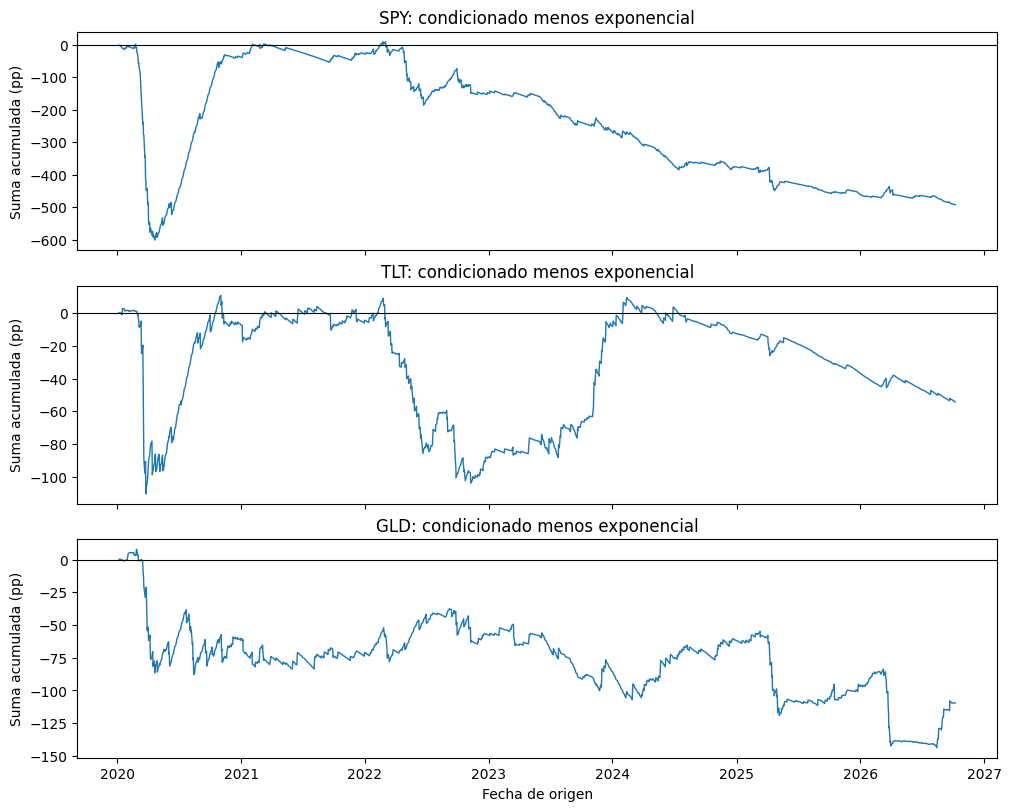

year,year_status,symbol,origins,mean_difference_pp,cumulative_contribution_pp
i64,str,str,i64,f64,f64
2020,"""full""","""GLD""",250,-0.241112,-60.278018
2021,"""full""","""GLD""",252,-0.042877,-10.804938
2022,"""full""","""GLD""",251,0.053426,13.410043
2023,"""full""","""GLD""",250,-0.110585,-27.646285
2024,"""full""","""GLD""",252,0.09303,23.443476
…,…,…,…,…,…
2022,"""full""","""TLT""",251,-0.332483,-83.453338
2023,"""full""","""TLT""",250,0.320726,80.181566
2024,"""full""","""TLT""",252,-0.019318,-4.868186


symbol,full_mean_difference_pp,trimmed_mean_difference_pp,excluded_dates
str,f64,f64,i64
"""GLD""",-0.064534,0.069124,17
"""SPY""",-0.289918,0.079291,17
"""TLT""",-0.032013,0.075242,17


symbol,block_length_sessions,mean_difference_pp,ci_lower_pp,ci_upper_pp
str,i64,f64,f64,f64
"""GLD""",10,-0.064534,-0.200625,0.060622
"""GLD""",20,-0.064534,-0.211213,0.06626
"""GLD""",40,-0.064534,-0.22217,0.057124
"""SPY""",10,-0.289918,-0.789098,0.139721
"""SPY""",20,-0.289918,-0.944005,0.243235
"""SPY""",40,-0.289918,-1.059401,0.343546
"""TLT""",10,-0.032013,-0.179062,0.091901
"""TLT""",20,-0.032013,-0.189953,0.102172
"""TLT""",40,-0.032013,-0.197623,0.122965


control,result
str,str
"""dates_aligned_unique_and_order…","""PASS"""
"""means_reproduce_block9""","""PASS"""
"""annual_counts_and_contribution…","""PASS"""
"""bootstrap_reproducible_finite_…","""PASS"""
"""block9_arrays_preserved""","""PASS"""


SPY: full mean=-0.2899 pp; after excluding 17 high-|d| dates=+0.0793 pp; the 20-session bootstrap interval includes zero, so the score difference remains uncertain.
TLT: full mean=-0.0320 pp; after excluding 17 high-|d| dates=+0.0752 pp; the 20-session bootstrap interval includes zero, so the score difference remains uncertain.
GLD: full mean=-0.0645 pp; after excluding 17 high-|d| dates=+0.0691 pp; the 20-session bootstrap interval includes zero, so the score difference remains uncertain.


In [8]:
import matplotlib.pyplot as plt

BOOTSTRAP_BLOCK_LENGTHS = (10, 20, 40)
BOOTSTRAP_REPLICATES = 10_000
BOOTSTRAP_SEED = 20_261_009
BOOTSTRAP_CONFIDENCE = 0.95
INFLUENCE_FRACTION = 0.01
temporal_symbols = ['SPY', 'TLT', 'GLD']
temporal_indices = np.array([returns.columns[1:].index(symbol) for symbol in temporal_symbols])
temporal_dates = np.asarray(h1_origin_dates)
temporal_differences = paired_score_difference[:, temporal_indices]
block9_difference_fingerprint = array_fingerprint(paired_score_difference)

def moving_block_bootstrap_means(values, block_length, replicates, seed, batch_size=250):
    values = np.asarray(values, dtype=float)
    if values.ndim != 2 or not np.isfinite(values).all() or not (1 <= block_length <= len(values)):
        raise ValueError('values must be finite T x N and block_length must be within 1..T.')
    n, instruments = values.shape; blocks_per_replica = int(np.ceil(n / block_length)); max_start = n - block_length
    rng = np.random.Generator(np.random.PCG64(seed))
    means = np.empty((replicates, instruments), dtype=float)
    offsets = np.arange(block_length, dtype=int)
    for start in range(0, replicates, batch_size):
        stop = min(start + batch_size, replicates); starts = rng.integers(0, max_start + 1, size=(stop - start, blocks_per_replica))
        indices = (starts[:, :, None] + offsets).reshape(stop - start, -1)[:, :n]
        means[start:stop] = values[indices].mean(axis=1)
    return means

if temporal_dates.shape[0] != 1698 or len(set(temporal_dates)) != len(temporal_dates) or list(temporal_dates) != sorted(temporal_dates):
    raise AssertionError('The chronological paired differential dates are not unique and ordered.')
years = np.array([d.year for d in temporal_dates], dtype=int)
annual_rows = []
for year in np.unique(years):
    mask = years == year
    for j, symbol in enumerate(temporal_symbols):
        annual_rows.append({'year': int(year), 'year_status': 'partial' if year == 2026 else 'full', 'symbol': symbol, 'origins': int(mask.sum()), 'mean_difference': float(temporal_differences[mask, j].mean()), 'cumulative_contribution': float(temporal_differences[mask, j].sum())})
annual_difference_summary = pl.DataFrame(annual_rows)

influence_count = int(np.ceil(INFLUENCE_FRACTION * len(temporal_dates)))
influence_rows = []
for j, symbol in enumerate(temporal_symbols):
    removal_indices = np.argsort(np.abs(temporal_differences[:, j]), kind='stable')[-influence_count:]
    retained = np.ones(len(temporal_dates), dtype=bool); retained[removal_indices] = False
    influence_rows.append({'symbol': symbol, 'full_mean_difference': float(temporal_differences[:, j].mean()), 'trimmed_mean_difference': float(temporal_differences[retained, j].mean()), 'excluded_dates': influence_count})
influence_summary = pl.DataFrame(influence_rows)

bootstrap_results = {}
bootstrap_rows = []
for block_length in BOOTSTRAP_BLOCK_LENGTHS:
    seed = BOOTSTRAP_SEED + block_length
    replicate_means = moving_block_bootstrap_means(temporal_differences, block_length, BOOTSTRAP_REPLICATES, seed)
    replay_means = moving_block_bootstrap_means(temporal_differences, block_length, BOOTSTRAP_REPLICATES, seed)
    if not np.array_equal(replicate_means, replay_means):
        raise AssertionError(f'Bootstrap is not reproducible for block length {block_length}.')
    bootstrap_results[block_length] = replicate_means
    lower, upper = np.quantile(replicate_means, [(1.0 - BOOTSTRAP_CONFIDENCE) / 2.0, 1.0 - (1.0 - BOOTSTRAP_CONFIDENCE) / 2.0], axis=0)
    for j, symbol in enumerate(temporal_symbols):
        bootstrap_rows.append({'symbol': symbol, 'block_length_sessions': block_length, 'mean_difference': float(temporal_differences[:, j].mean()), 'ci_lower': float(lower[j]), 'ci_upper': float(upper[j])})
bootstrap_summary = pl.DataFrame(bootstrap_rows)

annual_counts = annual_difference_summary.group_by('symbol').agg(pl.col('origins').sum().alias('origins'))
annual_contributions = annual_difference_summary.group_by('symbol').agg(pl.col('cumulative_contribution').sum().alias('summed_contribution'))
annual_count_by_symbol = {row['symbol']: row['origins'] for row in annual_counts.to_dicts()}
annual_contribution_by_symbol = {row['symbol']: row['summed_contribution'] for row in annual_contributions.to_dicts()}
mean_from_block9 = np.array([mean_score_difference[index] for index in temporal_indices])
temporal_controls = {
    'dates_aligned_unique_and_ordered': temporal_differences.shape == (1698, 3) and len(set(temporal_dates)) == 1698 and list(temporal_dates) == sorted(temporal_dates),
    'means_reproduce_block9': np.allclose(temporal_differences.mean(axis=0), mean_from_block9, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'annual_counts_and_contributions_reconcile': np.array_equal(np.array([annual_count_by_symbol[symbol] for symbol in temporal_symbols]), np.full(3, len(temporal_dates))) and np.allclose(np.array([annual_contribution_by_symbol[symbol] for symbol in temporal_symbols]), temporal_differences.sum(axis=0), atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'bootstrap_reproducible_finite_and_aligned': all(values.shape == (BOOTSTRAP_REPLICATES, 3) and np.isfinite(values).all() for values in bootstrap_results.values()),
    'block9_arrays_preserved': block9_difference_fingerprint == array_fingerprint(paired_score_difference),
}
if not all(temporal_controls.values()):
    raise AssertionError([name for name, passed in temporal_controls.items() if not passed])

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, constrained_layout=True)
for axis, symbol, j in zip(axes, temporal_symbols, range(3)):
    axis.plot(temporal_dates, 100.0 * np.cumsum(temporal_differences[:, j]), linewidth=1.0)
    axis.axhline(0.0, color='black', linewidth=0.8)
    axis.set_ylabel('Suma acumulada (pp)'); axis.set_title(f'{symbol}: condicionado menos exponencial')
axes[-1].set_xlabel('Fecha de origen')
plt.show()

annual_display = annual_difference_summary.with_columns([(100.0 * pl.col('mean_difference')).alias('mean_difference_pp'), (100.0 * pl.col('cumulative_contribution')).alias('cumulative_contribution_pp')]).select(['year', 'year_status', 'symbol', 'origins', 'mean_difference_pp', 'cumulative_contribution_pp']).sort(['symbol', 'year'])
influence_display = influence_summary.with_columns([(100.0 * pl.col('full_mean_difference')).alias('full_mean_difference_pp'), (100.0 * pl.col('trimmed_mean_difference')).alias('trimmed_mean_difference_pp')]).select(['symbol', 'full_mean_difference_pp', 'trimmed_mean_difference_pp', 'excluded_dates']).sort('symbol')
bootstrap_display = bootstrap_summary.with_columns([(100.0 * pl.col('mean_difference')).alias('mean_difference_pp'), (100.0 * pl.col('ci_lower')).alias('ci_lower_pp'), (100.0 * pl.col('ci_upper')).alias('ci_upper_pp')]).select(['symbol', 'block_length_sessions', 'mean_difference_pp', 'ci_lower_pp', 'ci_upper_pp']).sort(['symbol', 'block_length_sessions'])
display(annual_display)
display(influence_display)
display(bootstrap_display)
display(pl.DataFrame({'control': list(temporal_controls), 'result': ['PASS' if passed else 'FAIL' for passed in temporal_controls.values()]}))
for symbol in temporal_symbols:
    principal = bootstrap_display.filter((pl.col('symbol') == symbol) & (pl.col('block_length_sessions') == 20)).to_dicts()[0]
    influence = influence_display.filter(pl.col('symbol') == symbol).to_dicts()[0]
    if principal['ci_upper_pp'] < 0.0:
        reading = 'the 20-session bootstrap interval stays below zero for this retrospective score comparison'
    elif principal['ci_lower_pp'] > 0.0:
        reading = 'the 20-session bootstrap interval stays above zero for this retrospective score comparison'
    else:
        reading = 'the 20-session bootstrap interval includes zero, so the score difference remains uncertain'
    print(f"{symbol}: full mean={principal['mean_difference_pp']:+.4f} pp; after excluding {influence['excluded_dates']} high-|d| dates={influence['trimmed_mean_difference_pp']:+.4f} pp; {reading}.")


## 11A. Preparación del primer pronóstico a cinco sesiones

**Pregunta.** ¿Qué debemos reconstruir antes de simular un intervalo a cinco sesiones cuando el estado VIX puede cambiar entre pasos?

Usamos el primer origen elegible para $H=5$: **2020-01-07**. El ajuste contiene exclusivamente las 504 filas alineadas disponibles hasta 2020-01-06 y mantiene $\tau=1102$ sesiones. Para ese ajuste reconstruimos, sin reutilizar objetos de muestra completa, los cortes VIX, los momentos crisp y las tres columnas de probabilidades condicionadas $Q$.

Cada triple histórico conserva: estado de entrada (VIX de $x-2$), vector conjunto de 125 retornos de la sesión $x$, y estado de salida (VIX de $x-1$). Entrada y salida se clasifican con los mismos cortes del ajuste. Esta celda todavía no genera trayectorias ni recupera retornos posteriores al origen.

In [9]:
H5_PREPARATION_TOLERANCE = 1e-12
h5_first_origin_row = eligible_tables[5].head(1).to_dicts()[0]
h5_origin = h5_first_origin_row['origin_date']
h5_origin_position = cal.index(h5_origin)
h5_fit_end = cal[h5_origin_position - 1]
if h5_origin != date(2020, 1, 7) or h5_fit_end != date(2020, 1, 6):
    raise AssertionError(f'Unexpected first H=5 origin or fit end: {h5_origin}, {h5_fit_end}.')

# The fitting sample is selected only by its admissible return dates; no evaluated return is read here.
h5_state_rows = audit.filter(pl.col('return_date') <= h5_fit_end).sort('return_date')
h5_fit_dates = h5_state_rows['return_date'].to_list()
h5_fit_ids = h5_state_rows['return_row_id'].to_list()
h5_matrix_rows = returns.filter(pl.col('session_date').is_in(h5_fit_dates)).sort('session_date')
h5_fit_simple = h5_matrix_rows.select(returns.columns[1:]).to_numpy().astype(float)
h5_fit_log = np.log1p(h5_fit_simple)
h5_fit_vix_entry_dates = h5_state_rows['vix_source_date'].to_list()
h5_fit_vix_entry = h5_state_rows['vix_close'].to_numpy().astype(float)
h5_exit_dates = h5_state_rows['return_start_date'].to_list()
h5_missing_exit_dates = [d for d in h5_exit_dates if d not in vix]
if h5_missing_exit_dates:
    raise RuntimeError(f'Missing raw VIX exit values for historical rows: {h5_missing_exit_dates[:5]}.')
h5_fit_vix_exit = np.array([float(vix[d]) for d in h5_exit_dates], dtype=float)
h5_positions = np.array([cal.index(d) for d in h5_fit_dates], dtype=int)
h5_initial_vix_date = h5_fit_end
if h5_initial_vix_date not in vix:
    raise RuntimeError(f'Missing initial VIX on {h5_initial_vix_date}.')
h5_initial_vix = float(vix[h5_initial_vix_date])

h5_input_controls = {
    'first_h5_origin_and_504_rows': h5_first_origin_row['fit_observations'] == M == 504 and len(h5_fit_dates) == M,
    'matrix_audit_dates_ids_and_symbols_match': h5_matrix_rows['session_date'].to_list() == h5_fit_dates and len(set(h5_fit_ids)) == M and tuple(returns.columns[1:]) == tuple(eligible['symbol'].to_list()),
    'all_fit_returns_and_entry_states_admissible': all(d <= h5_fit_end for d in h5_fit_dates) and all(d <= h5_fit_end for d in h5_fit_vix_entry_dates) and all(d <= h5_fit_end for d in h5_exit_dates),
    'calendar_triple_ordering': all(entry < exit_ < ret for entry, exit_, ret in zip(h5_fit_vix_entry_dates, h5_exit_dates, h5_fit_dates)),
    'entry_and_exit_vix_domains': np.isfinite(h5_fit_vix_entry).all() and np.isfinite(h5_fit_vix_exit).all() and np.all(h5_fit_vix_entry > 0.0) and np.all(h5_fit_vix_exit > 0.0),
    'positions_ordered': np.all(np.diff(h5_positions) > 0) and h5_positions[-1] == cal.index(h5_fit_end),
}
if not all(h5_input_controls.values()):
    raise AssertionError([name for name, passed in h5_input_controls.items() if not passed])

# Each reference probability uses only the 504 fitting observations and their calendar positions.
h5_uniform_weights = np.full(M, 1.0 / M)
h5_ages = h5_positions[-1] - h5_positions
h5_exponential_weights = np.exp(-np.log(2.0) * h5_ages / TAU)
h5_exponential_weights /= h5_exponential_weights.sum()
h5_p25, _ = empirical_discrete_quantile(h5_fit_vix_entry, 0.25)
h5_p75, _ = empirical_discrete_quantile(h5_fit_vix_entry, 0.75)
if not h5_p25 < h5_p75:
    raise RuntimeError('The H=5 fitting-state cuts are not distinct.')

def h5_state_group(values, lower_cut, upper_cut):
    values = np.asarray(values, dtype=float)
    return np.where(values <= lower_cut, 1, np.where(values <= upper_cut, 2, 3)).astype(int)

h5_entry_groups = h5_state_group(h5_fit_vix_entry, h5_p25, h5_p75)
h5_exit_groups = h5_state_group(h5_fit_vix_exit, h5_p25, h5_p75)
h5_initial_group = int(h5_state_group([h5_initial_vix], h5_p25, h5_p75)[0])
h5_Q = np.empty((M, 3), dtype=float)
h5_solutions, h5_group_rows = [], []
for h5_group in (1, 2, 3):
    h5_mask = h5_entry_groups == h5_group
    h5_count = int(h5_mask.sum())
    if h5_count == 0:
        raise RuntimeError(f'Empty crisp group {h5_group} in the H=5 fitting sample.')
    h5_crisp = h5_mask.astype(float) / h5_count
    h5_mu = float(h5_crisp @ h5_fit_vix_entry)
    h5_var = float(h5_crisp @ np.square(h5_fit_vix_entry - h5_mu))
    h5_std = float(np.sqrt(h5_var))
    if not h5_std > 0.0:
        raise RuntimeError(f'Zero VIX dispersion in crisp group {h5_group}.')
    h5_solution = entropy_pooling_solver(h5_fit_vix_entry, h5_exponential_weights, h5_mu, h5_std)
    h5_Q[:, h5_group - 1] = h5_solution['q']
    h5_q = h5_solution['q']; h5_a = h5_solution['a']; h5_b = h5_solution['b']; h5_gradient = h5_solution['gradient']; h5_eta = float(h5_solution['theta'][1])
    h5_obtained_mean = float(h5_q @ h5_fit_vix_entry)
    h5_obtained_second = float(h5_q @ np.square(h5_fit_vix_entry))
    h5_target_second = h5_mu**2 + h5_var
    h5_slack = float(1.0 - h5_q @ h5_b)
    h5_kkt_eta = abs(float(h5_gradient[1])) if h5_eta > EP_KKT_TOLERANCE else max(0.0, -float(h5_gradient[1]))
    h5_ok = (np.isfinite(h5_q).all() and np.all(h5_q >= 0.0) and np.isclose(h5_q.sum(), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE) and abs(float(h5_q @ h5_a)) <= EP_EQUALITY_TOLERANCE and h5_slack >= -EP_INEQUALITY_TOLERANCE and abs(float(h5_gradient[0])) <= EP_KKT_TOLERANCE and float(h5_gradient[1]) >= -EP_KKT_TOLERANCE and h5_kkt_eta <= EP_KKT_TOLERANCE and abs(h5_eta * float(h5_gradient[1])) <= EP_KKT_TOLERANCE and h5_obtained_second <= h5_target_second + EP_INEQUALITY_TOLERANCE * h5_std**2)
    if not h5_ok:
        raise RuntimeError(f"Entropy-pooling controls failed for H=5 group {h5_group}: case={h5_solution['case']}, eta={h5_eta}, gradient={h5_gradient}, slack={h5_slack}.")
    h5_solutions.append(h5_solution)
    h5_group_rows.append({'group': h5_group, 'crisp_rows': h5_count, 'target_mean': h5_mu, 'obtained_mean': h5_obtained_mean, 'max_variance': h5_var, 'obtained_variance': float(h5_obtained_second - h5_obtained_mean**2), 'case': h5_solution['case'], 'eta': h5_eta, 'equality_residual': float(h5_q @ h5_a), 'inequality_slack': h5_slack, 'kkt_lambda_residual': abs(float(h5_gradient[0])), 'kkt_eta_residual': h5_kkt_eta, 'N_eff': float(1.0 / np.sum(h5_q**2)), 'KL_to_exponential': float(np.sum(h5_q * (h5_solution['log_q'] - np.log(h5_exponential_weights))))})

# The initial-state column must recover the H=1 conditional limits already obtained from exactly this sample.
h5_initial_q = h5_Q[:, h5_initial_group - 1]
h5_h1_lower, _, _, h5_h1_lower_adjustment = weighted_discrete_quantile(np.expm1(h5_fit_log), h5_initial_q, 0.05)
h5_h1_upper, _, _, h5_h1_upper_adjustment = weighted_discrete_quantile(np.expm1(h5_fit_log), h5_initial_q, 0.95)
h5_h1_reference = first_run['forecast']
h5_triples = pl.DataFrame({'return_row_id': h5_fit_ids, 'return_date': h5_fit_dates, 'return_start_date': h5_exit_dates, 'vix_entry_date': h5_fit_vix_entry_dates, 'vix_entry_close': h5_fit_vix_entry, 'entry_group': h5_entry_groups, 'vix_exit_date': h5_exit_dates, 'vix_exit_close': h5_fit_vix_exit, 'exit_group': h5_exit_groups})
for h5_symbol in ['SPY', 'TLT', 'GLD']:
    h5_triples = h5_triples.with_columns(pl.Series(f'{h5_symbol}_log_return', h5_fit_log[:, returns.columns[1:].index(h5_symbol)]))
h5_preparation_controls = {
    **h5_input_controls,
    'three_q_columns_normalized_and_aligned': h5_Q.shape == (M, 3) and np.isfinite(h5_Q).all() and np.all(h5_Q >= 0.0) and np.allclose(h5_Q.sum(axis=0), 1.0, atol=EP_FUNCTION_TOLERANCE, rtol=EP_FUNCTION_TOLERANCE),
    'same_cuts_classify_entry_exit_and_initial': np.array_equal(h5_entry_groups, h5_state_group(h5_fit_vix_entry, h5_p25, h5_p75)) and np.array_equal(h5_exit_groups, h5_state_group(h5_fit_vix_exit, h5_p25, h5_p75)) and h5_initial_group in (1, 2, 3),
    'triples_preserve_q_order': h5_triples['return_date'].to_list() == h5_fit_dates and h5_triples['return_row_id'].to_list() == h5_fit_ids and h5_triples.height == h5_Q.shape[0],
    'initial_q_column_reproduces_h1_limits': np.allclose(h5_h1_lower, h5_h1_reference['bounds']['conditional_vix']['lower'], atol=H5_PREPARATION_TOLERANCE, rtol=H5_PREPARATION_TOLERANCE) and np.allclose(h5_h1_upper, h5_h1_reference['bounds']['conditional_vix']['upper'], atol=H5_PREPARATION_TOLERANCE, rtol=H5_PREPARATION_TOLERANCE),
}
if not all(h5_preparation_controls.values()):
    raise AssertionError([name for name, passed in h5_preparation_controls.items() if not passed])

display(pl.DataFrame({'origin': [h5_origin], 'fit_end': [h5_fit_end], 'fit_rows': [len(h5_fit_dates)], 'tau_sessions': [TAU], 'p25': [h5_p25], 'p75': [h5_p75], 'initial_vix_date': [h5_initial_vix_date], 'initial_vix': [h5_initial_vix], 'initial_group': [h5_initial_group]}))
display(pl.DataFrame(h5_group_rows))
display(pl.concat([h5_triples.head(3), h5_triples.tail(3)]))
display(pl.DataFrame({'control': list(h5_preparation_controls), 'result': ['PASS' if passed else 'FAIL' for passed in h5_preparation_controls.values()]}))
print(f'H=5 preparation complete: {len(h5_fit_dates)} admissible triples, three reconstructed Q columns, and no trajectories or future realization were generated. Maximum H=1 CDF endpoint adjustment: {max(np.max(np.abs(h5_h1_lower_adjustment)), np.max(np.abs(h5_h1_upper_adjustment))):.3e}.')


origin,fit_end,fit_rows,tau_sessions,p25,p75,initial_vix_date,initial_vix,initial_group
date,date,i64,i64,f64,f64,date,f64,i64
2020-01-07,2020-01-06,504,1102,12.93,18.06,2020-01-06,13.85,2


group,crisp_rows,target_mean,obtained_mean,max_variance,obtained_variance,case,eta,equality_residual,inequality_slack,kkt_lambda_residual,kkt_eta_residual,N_eff,KL_to_exponential
i64,i64,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64
1,127,12.108819,12.108819,0.688432,0.688432,"""ACTIVE_ETA_POSITIVE""",0.29521,-6.0715e-18,-2.2204e-16,6.0715e-18,2.2204e-16,131.11029,1.190395
2,251,15.134542,15.134542,2.078075,2.078075,"""ACTIVE_ETA_POSITIVE""",0.451356,3.5627e-16,-1.3323e-15,3.5627e-16,1.3323e-15,261.730448,0.485413
3,126,21.668413,21.668413,12.918334,12.918334,"""ACTIVE_ETA_POSITIVE""",0.431913,4.4778e-17,-2.2204e-16,4.4778e-17,2.2204e-16,127.655581,1.071204


return_row_id,return_date,return_start_date,vix_entry_date,vix_entry_close,entry_group,vix_exit_date,vix_exit_close,exit_group,SPY_log_return,TLT_log_return,GLD_log_return
i64,date,date,date,f64,i64,date,f64,i64,f64,f64,f64
1,2018-01-04,2018-01-03,2018-01-02,9.77,1,2018-01-03,9.15,1,0.004206,-0.000159,0.005114
2,2018-01-05,2018-01-04,2018-01-03,9.15,1,2018-01-04,9.22,1,0.006642,-0.00286,-0.001037
3,2018-01-08,2018-01-05,2018-01-04,9.22,1,2018-01-05,9.22,1,0.001827,-0.000637,-0.00016
502,2020-01-02,2019-12-31,2019-12-30,14.82,2,2019-12-31,13.78,2,0.009308,0.01123,0.007321
503,2020-01-03,2020-01-02,2019-12-31,13.78,2,2020-01-02,12.47,1,-0.007601,0.015283,0.013181
504,2020-01-06,2020-01-03,2020-01-02,12.47,1,2020-01-03,14.02,2,0.003808,-0.005695,0.010435


control,result
str,str
"""first_h5_origin_and_504_rows""","""PASS"""
"""matrix_audit_dates_ids_and_sym…","""PASS"""
"""all_fit_returns_and_entry_stat…","""PASS"""
"""calendar_triple_ordering""","""PASS"""
"""entry_and_exit_vix_domains""","""PASS"""
"""positions_ordered""","""PASS"""
"""three_q_columns_normalized_and…","""PASS"""
"""same_cuts_classify_entry_exit_…","""PASS"""
"""triples_preserve_q_order""","""PASS"""


H=5 preparation complete: 504 admissible triples, three reconstructed Q columns, and no trajectories or future realization were generated. Maximum H=1 CDF endpoint adjustment: 1.332e-15.
